In [1]:
import pandas as pd
from scipy.stats import mannwhitneyu, fisher_exact, pearsonr, spearmanr, kendalltau, wilcoxon
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score
import os
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
import textwrap
from tqdm import tqdm
import subprocess
from sklearn.metrics import roc_curve, auc
from sklearn.cluster import KMeans
import ants
from lifelines import KaplanMeierFitter, CoxPHFitter, utils
from lifelines.statistics import logrank_test
from lifelines.utils import concordance_index # C-index
from matplotlib.offsetbox import AnnotationBbox, TextArea, HPacker, VPacker
from matplotlib import cm
from sklearn.metrics import confusion_matrix
from statsmodels.stats.multitest import multipletests

In [2]:
# root = '/ssd_data1/syjeong/portable' # 170 서버
root = '/media/data/syjeong/GBM_RTA' # 169 서버

In [3]:
data_dir = f'{root}/data/only_initial'

In [4]:
palette  = {key:value for key, value in enumerate(plt.get_cmap("tab10").colors)}

In [5]:
pd.read_excel(f'{root}/excel_csv/GBM longituidinal samples TMM 2nd round.xlsx').columns

Index(['Study No.', '환자번호', '환자명', '성별', '처음수술당시나이',
       'RTA△group (Extend score)', 'Telomerase activity1',
       'Telomerase activity2', '△RTA% ratio', '처음수술일자', 'Pathology',
       'sample no', 'vials', 'Labelling', 'RTA', 'RTA(%)', 'TA/heated TA',
       'CCA Quantification (8hr/4hr)', 'C-circle', 'TMM', 'Unnamed: 20',
       'TERTp', 'ATRX', 'Ki-67', 'IDH1/2', 'EGFR', 'Unnamed: 26', 'MGMTp',
       '재수술일자', 'Pathology.1', 'sample no.1', 'vials.1', 'Labelling.1',
       'RTA.1', 'RTA(%).1', 'TA/heated TA.1', 'CCA Quantification',
       'C-circle.1', 'TMM.1', 'Unnamed: 39', 'TERTp.1', 'ATRX.1', 'Ki-67.1',
       'IDH1/2.1', 'EGFR.1', 'MGMTp.1', 'Blood', 'Labelling.2', 'Unnamed: 48',
       'OP1', 'CCRT', 'TMZ', 'OP2', 'RT', 'TMZ.1', 'CT', 'Unnamed: 56', '사망여부',
       '사망일', '생존확인', 'PFS(W)', 'OS(W)', 'PFS(m)', 'OS1(m)', 'OS2(m)'],
      dtype='object')

In [6]:
original_meta = pd.read_excel(f'{root}/excel_csv/GBM longituidinal samples TMM 2nd round.xlsx')
original_meta = original_meta[['환자번호', '성별', '처음수술당시나이', 'Telomerase activity1', 'Telomerase activity2', 'RTA△group (Extend score)', 'TERTp', 'MGMTp', 'CCRT', 'OP1', 'TERTp.1', 'MGMTp.1', 'OP2', 'PFS(W)', 'OS(W)', 'PFS(m)', 'OS1(m)', 'OS2(m)', '사망일']]
original_meta.rename({'환자번호':'ID', '성별':'sex', '처음수술당시나이':'age', 'RTA△group (Extend score)': 'RTA', 'Telomerase activity1':'TA1', 'Telomerase activity2':'TA2', '사망일':'event_observed', 'TERTp.1':'TERTp2', 'MGMTp.1':'MGMTp2'}, axis=1, inplace=True)
original_meta.set_index('ID', inplace=True)
original_meta.index = original_meta.index.astype(str)
original_meta['RTA_cont'] = original_meta['TA2'] - original_meta['TA1']
original_meta['event_observed'] = original_meta['event_observed'].map(lambda x: 0 if pd.isna(x) else 1)
original_meta['decrease'] = original_meta['RTA'].map(lambda x: 1 if x == 'D' else 0)
original_meta['increase'] = original_meta['RTA'].map(lambda x: 1 if x == 'I' else 0)

original_meta['TERTp'] = (original_meta['TERTp']=='mut').astype(int)
original_meta['MGMTp'] = (original_meta['MGMTp']=='methylation').astype(int)
original_meta['TERTp2'] = (original_meta['TERTp']=='mut').astype(int)
original_meta['MGMTp2'] = (original_meta['MGMTp']=='methylation').astype(int)
original_meta.CCRT = original_meta.CCRT.replace('O(Gy모름)', np.nan)
original_meta = original_meta.loc[original_meta.index.astype(str).isin(os.listdir(data_dir))]

original_meta = original_meta.loc[original_meta['OP1']=='GTR']
print(f'length of original_meta: {len(original_meta)}')
original_meta.columns

length of original_meta: 20


/tmp/ipykernel_464399/2260183660.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  original_meta.CCRT = original_meta.CCRT.replace('O(Gy모름)', np.nan)


Index(['sex', 'age', 'TA1', 'TA2', 'RTA', 'TERTp', 'MGMTp', 'CCRT', 'OP1',
       'TERTp2', 'MGMTp2', 'OP2', 'PFS(W)', 'OS(W)', 'PFS(m)', 'OS1(m)',
       'OS2(m)', 'event_observed', 'RTA_cont', 'decrease', 'increase'],
      dtype='object')

In [7]:
print('\nUnivariate1')
cph = CoxPHFitter()
for survival_target in ['OS(W)', 'PFS(W)']:
    print(survival_target)
    for data in ['TA1', 'TERTp', 'MGMTp']:
        df = original_meta[[survival_target, 'event_observed', data]].copy() 
        cph.fit(df, duration_col=survival_target, event_col='event_observed')
        df['partial_hazard'] = cph.predict_partial_hazard(df)
        c_index = concordance_index(df[survival_target], -df['partial_hazard'], df['event_observed'])
        print(f'{data} p-val: {round(cph.summary["p"][data], 3)}, HR ratio: {cph.summary["exp(coef)"][data]}')


Univariate1
OS(W)
TA1 p-val: 0.115, HR ratio: 1.0059570532259563
TERTp p-val: 0.01, HR ratio: 5.591847479097641
MGMTp p-val: 0.007, HR ratio: 0.1681422237122736
PFS(W)
TA1 p-val: 0.258, HR ratio: 1.0046919693506136
TERTp p-val: 0.968, HR ratio: 0.9802936104881206
MGMTp p-val: 0.04, HR ratio: 0.30216788068376177


In [8]:
print('\nMultivariate1')
cph = CoxPHFitter()
for survival_target in ['OS(W)', 'PFS(W)']:
    df = original_meta[[survival_target, 'event_observed', 'TERTp', 'MGMTp']].copy() 
    cph.fit(df, duration_col=survival_target, event_col='event_observed')
    df['partial_hazard'] = cph.predict_partial_hazard(df)
    c_index = concordance_index(df[survival_target], -df['partial_hazard'], df['event_observed'])
    print(f'{survival_target} C-index: {c_index:.4f}')
    variables = ['TERTp', 'MGMTp']
    bootstrap_results = {var: [] for var in variables}
    for v in variables:
        print(f'{v} p-val: {cph.summary["p"][v]}, HR ratio: {cph.summary["exp(coef)"][v]}')


Multivariate1
OS(W) C-index: 0.7751
TERTp p-val: 0.005898568775597462, HR ratio: 8.832984408079495
MGMTp p-val: 0.0036220081002748894, HR ratio: 0.11420312193827709
PFS(W) C-index: 0.6658
TERTp p-val: 0.6604716155340028, HR ratio: 1.248640208540405
MGMTp p-val: 0.03779553898259337, HR ratio: 0.28431303919264334


In [9]:
print('\nMultivariate1')
cph = CoxPHFitter()
for survival_target in ['OS(W)', 'PFS(W)']:
    df = original_meta[[survival_target, 'event_observed', 'TA1', 'TERTp', 'MGMTp']].copy() 
    cph.fit(df, duration_col=survival_target, event_col='event_observed')
    df['partial_hazard'] = cph.predict_partial_hazard(df)
    c_index = concordance_index(df[survival_target], -df['partial_hazard'], df['event_observed'])
    print(f'{survival_target} C-index: {c_index:.4f}')
    variables = ['TA1', 'TERTp', 'MGMTp']
    bootstrap_results = {var: [] for var in variables}
    for v in variables:
        print(f'{v} p-val: {cph.summary["p"][v]}, HR ratio: {cph.summary["exp(coef)"][v]}')


Multivariate1
OS(W) C-index: 0.8545
TA1 p-val: 0.007852046269469858, HR ratio: 1.0152266537446377
TERTp p-val: 0.0020864988164344704, HR ratio: 18.149099249129563
MGMTp p-val: 0.0030913882409325287, HR ratio: 0.06745098692845986
PFS(W) C-index: 0.6921
TA1 p-val: 0.2825130078340869, HR ratio: 1.004459229082403
TERTp p-val: 0.6213557853935338, HR ratio: 1.285493634868665
MGMTp p-val: 0.03865118945705253, HR ratio: 0.2829363667036119


In [10]:
print('\nMultivariate1')
cph = CoxPHFitter()
for survival_target in ['OS(W)', 'PFS(W)']: 
    df = original_meta[[survival_target, 'event_observed', 'TA1', 'MGMTp']].copy() 
    cph.fit(df, duration_col=survival_target, event_col='event_observed')
    df['partial_hazard'] = cph.predict_partial_hazard(df)
    c_index = concordance_index(df[survival_target], -df['partial_hazard'], df['event_observed'])
    print(f'{survival_target} C-index: {c_index:.4f}')
    print(f'TA1 p-val: {cph.summary["p"]["TA1"]}, HR ratio: {cph.summary["exp(coef)"]["TA1"]}')
    # print(f'TERTp p-val: {cph.summary["p"]["TERTp"]}, HR ratio: {cph.summary["exp(coef)"]["TERTp"]}')
    print(f'MGMTp p-val: {cph.summary["p"]["MGMTp"]}, HR ratio: {cph.summary["exp(coef)"]["MGMTp"]}')


Multivariate1
OS(W) C-index: 0.8016
TA1 p-val: 0.09392184581346291, HR ratio: 1.0059356424732016
MGMTp p-val: 0.005768124057193396, HR ratio: 0.15725973150693204
PFS(W) C-index: 0.6868
TA1 p-val: 0.2932256257739324, HR ratio: 1.004159442991987
MGMTp p-val: 0.04217884559764038, HR ratio: 0.30237339118418743


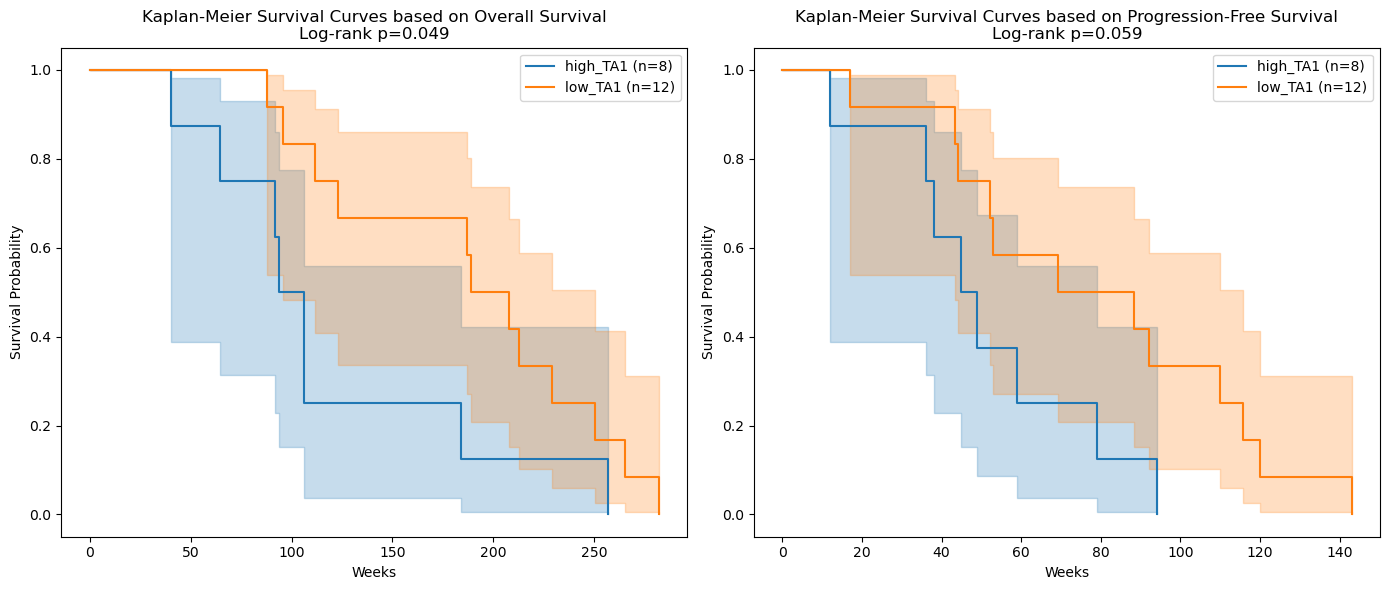

In [13]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))


survival_target = 'OS(W)'
df = original_meta[[survival_target, 'event_observed', 'TA1']].copy()
cph.fit(df, duration_col=survival_target, event_col='event_observed')
df['partial_hazard'] = cph.predict_partial_hazard(df)
median_hazard = 35
high_hazard = df[df['TA1'] > median_hazard].copy() 
low_hazard = df[df['TA1'] <= median_hazard].copy() 

kmf_D = KaplanMeierFitter()
kmf_ND = KaplanMeierFitter()
kmf_D.fit(high_hazard[survival_target], high_hazard['event_observed'], label=f'high_TA1 (n={len(high_hazard)})')
kmf_ND.fit(low_hazard[survival_target], low_hazard['event_observed'], label=f'low_TA1 (n={len(low_hazard)})')

kmf_D.plot_survival_function(ax=axs[0])
kmf_ND.plot_survival_function(ax=axs[0])
results = logrank_test(high_hazard[survival_target], low_hazard[survival_target],
                       event_observed_A=high_hazard['event_observed'],
                       event_observed_B=low_hazard['event_observed'])
axs[0].set_title(f"Kaplan-Meier Survival Curves based on Overall Survival\nLog-rank p={results.p_value:.3f}")
axs[0].set_xlabel("Weeks")
axs[0].set_ylabel("Survival Probability")


survival_target = 'PFS(W)'
df = original_meta[[survival_target, 'event_observed', 'TA1']].copy()
cph.fit(df, duration_col=survival_target, event_col='event_observed')
df['partial_hazard'] = cph.predict_partial_hazard(df)
high_hazard = df[df['TA1'] > median_hazard].copy() 
low_hazard = df[df['TA1'] <= median_hazard].copy() 

kmf_D = KaplanMeierFitter()
kmf_ND = KaplanMeierFitter()
kmf_D.fit(high_hazard[survival_target], high_hazard['event_observed'], label=f'high_TA1 (n={len(high_hazard)})')
kmf_ND.fit(low_hazard[survival_target], low_hazard['event_observed'], label=f'low_TA1 (n={len(low_hazard)})')

kmf_D.plot_survival_function(ax=axs[1])
kmf_ND.plot_survival_function(ax=axs[1])
results = logrank_test(high_hazard[survival_target], low_hazard[survival_target],
                       event_observed_A=high_hazard['event_observed'],
                       event_observed_B=low_hazard['event_observed'])
axs[1].set_title(f"Kaplan-Meier Survival Curves based on Progression-Free Survival\nLog-rank p={results.p_value:.3f}")
axs[1].set_xlabel("Weeks")
axs[1].set_ylabel("Survival Probability")

plt.tight_layout()
plt.legend()
# plt.savefig(f"{root}/figures/FigureS1_TA_survival.png", format="png", dpi=600, bbox_inches='tight')
plt.show()


In [14]:
survival_target = 'OS(W)' 
survival = original_meta[[survival_target, 'event_observed', 'TA1', 'TA2', 'TERTp', 'MGMTp']] 
survival = survival.merge(original_meta[['sex', 'age', 'RTA', 'RTA_cont', 'OP1']], left_index=True, right_index=True)
survival['high_TA1'] = 0

survival.loc[survival['TA1']>35, 'high_TA1'] = 1
high_TA1 = survival[survival['high_TA1']==1]
low_TA1 = survival[survival['high_TA1']==0]

increase = survival[survival['RTA']=='I']
non_increase = survival[survival['RTA']!='I']

decrease = survival[survival['RTA']=='D']
non_decrease = survival[survival['RTA']!='D']

display(survival.reset_index(drop=True))

,OS(W),event_observed,TA1,TA2,TERTp,MGMTp,sex,age,RTA,RTA_cont,OP1,high_TA1
0,40.000000,1,67.0,0.0,1,0,M,73,D,-67.0,GTR,1
1,257.000000,1,84.6,0.1,0,1,M,47,D,-84.5,GTR,1
2,106.000000,1,60.1,0.0,1,0,M,51,D,-60.1,GTR,1
3,187.000000,1,32.2,14.8,1,1,M,65,D,-17.4,GTR,0
4,92.000000,1,69.0,2.8,1,0,F,46,D,-66.2,GTR,1
5,184.000000,1,48.9,9.9,1,0,F,48,D,-39.0,GTR,1
6,229.000000,1,35.0,0.0,1,1,F,49,D,-35.0,GTR,0
7,94.000000,1,68.2,6.3,1,0,M,61,D,-61.9,GTR,1
8,106.000000,1,244.7,39.7,0,0,F,42,D,-205.0,GTR,1
9,207.857143,1,7.4,0.0,1,1,M,65,D,-7.4,GTR,0


In [15]:
print('Sex')
print('TA1:', fisher_exact([[len(high_TA1[high_TA1['sex']=='M']), len(high_TA1[high_TA1['sex']!='M'])], 
              [len(low_TA1[low_TA1['sex']=='M']), len(low_TA1[low_TA1['sex']!='M'])]]))
print('decrease:', fisher_exact([[len(decrease[decrease['sex']=='M']), len(decrease[decrease['sex']!='M'])], 
              [len(non_decrease[non_decrease['sex']=='M']), len(non_decrease[non_decrease['sex']!='M'])]]))

Sex
TA1: SignificanceResult(statistic=0.7142857142857143, pvalue=1.0)
decrease: SignificanceResult(statistic=1.4, pvalue=1.0)


In [16]:
print('TERTp mut')
print('TA1:', fisher_exact([[len(high_TA1[high_TA1['TERTp']==1]), len(high_TA1[high_TA1['TERTp']!=1])],
              [len(low_TA1[low_TA1['TERTp']==1]), len(low_TA1[low_TA1['TERTp']!=1])]]))
print('decrease:', fisher_exact([[len(decrease[decrease['TERTp']==1]), len(decrease[decrease['TERTp']!=1])], 
              [len(non_decrease[non_decrease['TERTp']==1]), len(non_decrease[non_decrease['TERTp']!=1])]]))

TERTp mut
TA1: SignificanceResult(statistic=2.142857142857143, pvalue=0.6424148606811146)
decrease: SignificanceResult(statistic=8.333333333333334, pvalue=0.062332301341589263)


In [17]:
print('MGMTp methylation')
print('TA1:', fisher_exact([[len(high_TA1[high_TA1['MGMTp']==1]), len(high_TA1[high_TA1['MGMTp']!=1])], 
                            [len(low_TA1[low_TA1['MGMTp']==1]), len(low_TA1[low_TA1['MGMTp']!=1])]]))
print('decrease:', fisher_exact([[len(decrease[decrease['MGMTp']==1]), len(decrease[decrease['MGMTp']!=1])], 
              [len(non_decrease[non_decrease['MGMTp']==1]), len(non_decrease[non_decrease['MGMTp']!=1])]]))

MGMTp methylation
TA1: SignificanceResult(statistic=0.2, pvalue=0.32456140350877194)
decrease: SignificanceResult(statistic=1.5, pvalue=1.0)


In [18]:
print('Age')
print('TA1:', mannwhitneyu(high_TA1.age, low_TA1.age))
print('decrease:', mannwhitneyu(decrease.age, non_decrease.age))

Age
TA1: MannwhitneyuResult(statistic=40.5, pvalue=0.5885932719036583)
decrease: MannwhitneyuResult(statistic=52.5, pvalue=0.7572668951460247)


In [19]:
print('TA1')
print('TA1:', mannwhitneyu(high_TA1.TA1, low_TA1.TA1))
print('decrease:', mannwhitneyu(decrease.TA1, non_decrease.TA1))

TA1
TA1: MannwhitneyuResult(statistic=96.0, pvalue=0.00023455467501049587)
decrease: MannwhitneyuResult(statistic=93.0, pvalue=0.0005684668718268336)


In [20]:
print('TA2')
print('TA1:', mannwhitneyu(high_TA1.TA2, low_TA1.TA2))
print('decrease:', mannwhitneyu(decrease.TA2, non_decrease.TA2))

TA2
TA1: MannwhitneyuResult(statistic=53.0, pvalue=0.7226868586358804)
decrease: MannwhitneyuResult(statistic=39.0, pvalue=0.5026599919743169)


In [21]:
mannwhitneyu(original_meta.loc[original_meta['decrease']==1].CCRT.dropna(),
original_meta.loc[original_meta['decrease']==0].CCRT)

MannwhitneyuResult(statistic=30.5, pvalue=0.230594734567378)

In [22]:
pre_total = pd.DataFrame()
for subj in tqdm(sorted(original_meta.index)):
    directory = os.path.join(data_dir, subj, '1')

    df = pd.DataFrame()
    for file_name, name in zip(['flair_vox.nii.gz', 'rCBV_vox.nii.gz', 'adc_vox.nii.gz', 't1ce_vox.nii.gz', 
                                'flair_rad.nii.gz', 'rCBV_rad.nii.gz', 'adc_rad.nii.gz', 't1ce_rad.nii.gz', 
                                ], 
                         ['flair', 'cbv', 'adc', 't1ce', 
                          'flair_normed', 'cbv_normed', 'adc_normed', 't1ce_normed', 
                          ]):
        img = ants.image_read(os.path.join(directory, file_name))
        img = img.numpy()
        img = img.flatten()
        df = pd.concat([df, pd.DataFrame({name:img})], axis=1)

    for file_name, name in zip(['NE_tumor_mask.nii.gz', 'CE_tumor_mask.nii.gz'], ['NE', 'CE']):
        img = ants.image_read(os.path.join(directory, file_name))
        img = img.numpy()
        img = img.flatten()
        img = pd.Series(img)
        img = img[img>0].index
        df[name] = None
        df.loc[img, name] = img

    df = df[(~pd.isnull(df['NE'])) | (~pd.isnull(df['CE']))]
    df['subj'] = subj
    df['flair_adc'] = (df['flair_normed']+10000) / (df['adc_normed']+10000)
    df['cbv_adc'] = (df['cbv_normed']+10000) / (df['adc_normed']+10000)

    pre_total = pd.concat([pre_total, df], axis=0)
    
pre_total['NE1CE0'] = pre_total.apply(lambda row: 1 if row['NE'] is not None else 0, axis=1)
# leave only valid voxels
pre_total = pre_total[(pre_total['adc']>0)&(pre_total['cbv']>0)&(pre_total['flair']>0)&(pre_total['t1ce']>0)]
# 99.9 percentile as outliers
percentiles = pre_total[['adc', 'cbv', 'flair', 't1ce', 'flair_adc', 'cbv_adc']].quantile(0.999)
# remove outlier
pre_total = pre_total[
    (pre_total['adc'] <= percentiles['adc']) &
    (pre_total['cbv'] <= percentiles['cbv']) &
    (pre_total['flair'] <= percentiles['flair']) &
    (pre_total['t1ce'] <= percentiles['t1ce']) # &
]

total_range = {'cbv_min': pre_total['cbv_normed'].min(), 
               'cbv_max': pre_total['cbv_normed'].max(),
               'adc_min': pre_total['adc_normed'].min(), 
               'adc_max': pre_total['adc_normed'].max()}

common_range = {'cbv_min': total_range['cbv_min'], 
               'cbv_max': total_range['cbv_max'],
               'adc_min': total_range['adc_min'], 
               'adc_max': total_range['adc_max']}

for subj in tqdm(sorted(original_meta.index)):
    if not os.path.isdir(os.path.join(data_dir, subj)): continue

    df = pre_total[pre_total['subj']==subj]
    cbv_min = df.cbv_normed.min()
    if cbv_min > common_range['cbv_min']:
        common_range['cbv_min'] = cbv_min

    cbv_max = df.cbv_normed.max()
    if cbv_max < common_range['cbv_max']:
        common_range['cbv_max'] = cbv_max

    adc_min = df.adc_normed.min()
    if adc_min > common_range['adc_min']:
        common_range['adc_min'] = adc_min

    adc_max = df.adc_normed.max()
    if adc_max < common_range['adc_max']:
        common_range['adc_max'] = adc_max


  0%|          | 0/20 [00:00<?, ?it/s]

100%|██████████| 20/20 [00:00<00:00, 492.34it/s]


(-201.8782501220703, 447.5259094238281)

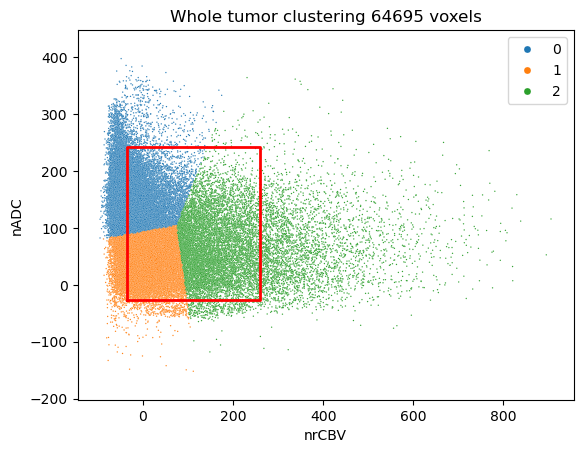

In [23]:
n_cluster=3
df = pre_total[(pre_total['cbv_normed']>common_range['cbv_min'])&
               (pre_total['adc_normed']>common_range['adc_min'])&
               (pre_total['cbv_normed']<common_range['cbv_max'])&
               (pre_total['adc_normed']<common_range['adc_max'])]

kmeans = KMeans(n_clusters = n_cluster, random_state=2 # 123
                      )

kmeans.fit(df[['cbv_normed', 'adc_normed']]) 

pre_wt_center = kmeans.cluster_centers_

pre_total['wt_kmeans'] = kmeans.predict(pre_total[['cbv_normed', 'adc_normed']])
sns.scatterplot(data=pre_total, x='cbv_normed', y='adc_normed', hue='wt_kmeans', s=1, palette=palette)
plt.title(f'Whole tumor clustering {len(pre_total)} voxels')
plt.xlabel('nrCBV')
plt.ylabel('nADC')
plt.legend(markerscale=5)
plt.plot([common_range['cbv_min'], common_range['cbv_min'], common_range['cbv_max'], common_range['cbv_max'], common_range['cbv_min']], 
         [common_range['adc_min'], common_range['adc_max'], common_range['adc_max'], common_range['adc_min'], common_range['adc_min']], 
         'r-', 
         linewidth=2)
plt.xlim(total_range['cbv_min']-50, total_range['cbv_max']+50)
plt.ylim(total_range['adc_min']-50, total_range['adc_max']+50)

In [24]:
total = {}
total['initial'] = pre_total

/tmp/ipykernel_464399/4191416163.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('jet')


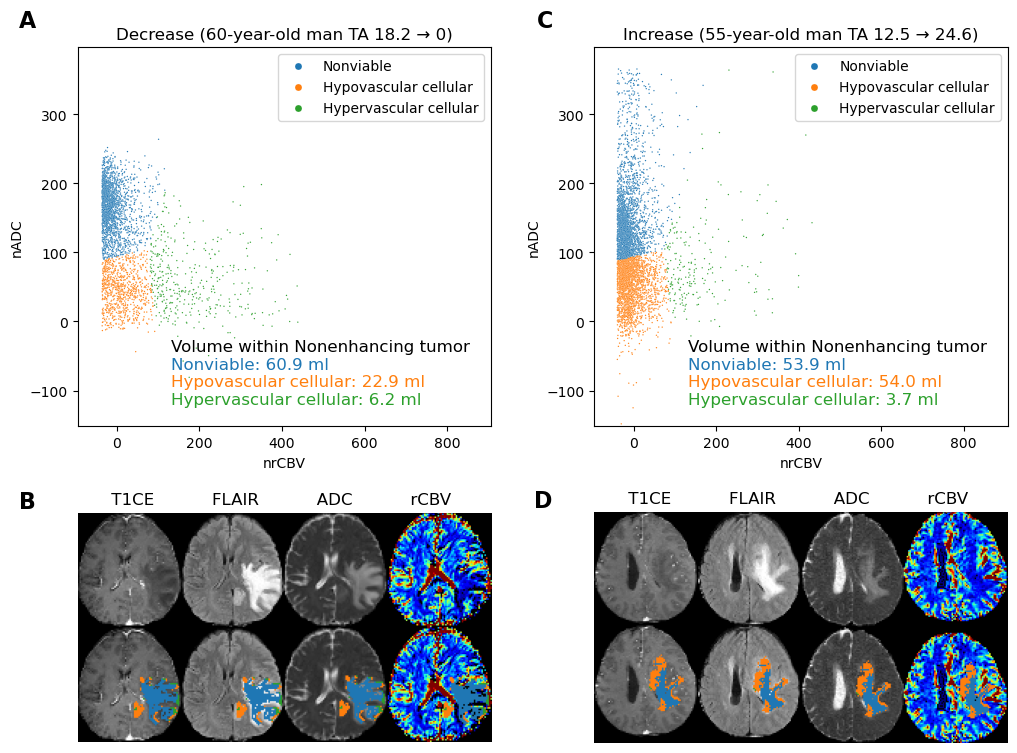

In [25]:
cmap = cm.get_cmap('jet')

row, col = 2, 2 
fig, ax = plt.subplots(nrows=row, ncols=col, figsize=(col*6, row*5))
plt.subplots_adjust(wspace=0.4, hspace=0.4)

xlim = (total_range['cbv_min'], total_range['cbv_max'])
ylim = (total_range['adc_min'], total_range['adc_max'])

subjs = ['51788810', '13759687']
titles = ['Decrease (60-year-old man TA 18.2 → 0)', 'Increase (55-year-old man TA 12.5 → 24.6)']

for i, subj in enumerate(subjs):
    pre_to_plot = total['initial'].loc[total['initial']['subj'] == subj].copy() 
    pre_to_plot['wt_kmeans_named'] = pre_to_plot['wt_kmeans'].map({0:'Nonviable', 
                                                                   1: 'Hypovascular cellular',
                                                                   2: 'Hypervascular cellular'})
    sns.scatterplot(
        data=pre_to_plot,
        x='cbv_normed',
        y='adc_normed',
        s=1,
        hue='wt_kmeans_named',
        hue_order=['Nonviable', 'Hypovascular cellular', 'Hypervascular cellular'],
        palette={'Nonviable':palette[0], 'Hypovascular cellular':palette[1], 'Hypervascular cellular':palette[2]},
        ax=ax[0, i]
    ).set(title=titles[i], xlim=xlim, ylim=ylim)
    ax[0, i].legend(markerscale=5)
    ax[0, i].set_xlabel('nrCBV')
    ax[0, i].set_ylabel('nADC')

text0 = TextArea("Volume within Nonenhancing tumor", textprops=dict(color="black", fontsize=12))
text1 = TextArea("Nonviable: 60.9 ml", textprops=dict(color=palette[0], fontsize=12))
text2 = TextArea("Hypovascular cellular: 22.9 ml", textprops=dict(color=palette[1], fontsize=12))
text3 = TextArea("Hypervascular cellular: 6.2 ml", textprops=dict(color=palette[2], fontsize=12))

packed = VPacker(children=[text0, text1, text2, text3], align="baseline", pad=0, sep=2)

ann = AnnotationBbox(packed, (0.95, 0.05), xycoords='axes fraction', box_alignment=(1, 0), frameon=False)

ax[0, 0].add_artist(ann)

text0 = TextArea("Volume within Nonenhancing tumor", textprops=dict(color="black", fontsize=12))
text1 = TextArea("Nonviable: 53.9 ml", textprops=dict(color=palette[0], fontsize=12))
text2 = TextArea("Hypovascular cellular: 54.0 ml", textprops=dict(color=palette[1], fontsize=12))
text3 = TextArea("Hypervascular cellular: 3.7 ml", textprops=dict(color=palette[2], fontsize=12))

packed = VPacker(children=[text0, text1, text2, text3], align="baseline", pad=0, sep=2)

ann = AnnotationBbox(packed, (0.95, 0.05), xycoords='axes fraction', box_alignment=(1, 0), frameon=False)

ax[0, 1].add_artist(ann)

i = 0
for subj, slice_num in [('51788810', 13), ('13759687', 11)]:
    concat_img = None
    title = ''
    for seq in ['t1ce', 'flair', 'adc', 'rCBV']: # 
        img = ants.image_read(os.path.join(data_dir, subj, '1', f'{seq}_vox.nii.gz')).numpy()
        if seq == 'rCBV':
            lower_bound = np.percentile(img, 0)
            upper_bound = np.percentile(img, 98)
            img = np.clip(img, lower_bound, upper_bound)
            img = (img - lower_bound) / (upper_bound - lower_bound)

            img_colored = cmap(img)[:, :, :, :3]
            img_colored = (img_colored * 255).astype(np.int32)
            img_colored[img<=0] = [0, 0, 0]
            
            masked = img_colored.copy()
            img = img_colored.copy()
        else:
            lower_bound = np.percentile(img, 0.1)
            upper_bound = np.percentile(img, 99.9)
            img = np.clip(img, lower_bound, upper_bound)
            img = (img - lower_bound) / (upper_bound - lower_bound)

            img = img * 255
            img = np.clip(img, 0, 255)
            masked = np.repeat(img[..., np.newaxis], 3, -1)
            img = np.repeat(img[..., np.newaxis], 3, -1)

        shape = masked.shape
        to_plot = total['initial'].loc[total['initial']['subj'] == subj].copy() 
        masked = masked.reshape(-1, shape[-1])
        for cluster in range(n_cluster):
            ind = to_plot.loc[to_plot['wt_kmeans'] == cluster]
            masked[ind.loc[ind['NE1CE0'] == 1, 'NE'].astype('int').values] = [int(p*255) for p in palette[cluster]]
        masked = masked.reshape(shape)
        img = img[:, :, slice_num]
        masked = masked[:, :, slice_num]
        img = img.astype(np.int32)
        masked = masked.astype(np.int32)
        img = np.rot90(img, k=1)
        masked = np.rot90(masked, k=1)
        coords = np.argwhere(np.any(img > 0, axis=-1))
        y0, x0 = coords.min(axis=0)
        y1, x1 = coords.max(axis=0) + 1 

        if concat_img is None:
            img = img[y0:y1, x0:x1]
            masked = masked[y0:y1, x0:x1]
            img = np.concatenate([img, masked], axis=0)
            concat_img = img.copy()
        else:
            y = y1-y0
            if 2*y < concat_img.shape[0]:
                img = img[y0:y1+concat_img.shape[0]-2*y, x0:x1]
                masked = masked[y0:y1, x0:x1]
                img = np.concatenate([img, masked], axis=0)
                concat_img = np.concatenate([concat_img, img], axis=1)
            elif 2*y > concat_img.shape[0]:
                img = img[y0:y1, x0:x1]
                masked = masked[y0:y1, x0:x1]
                img = np.concatenate([img, masked], axis=0)
                concat_img = np.pad(concat_img, ((0, 2*y-concat_img.shape[0]), (0, 0), (0, 0)), mode='constant', constant_values=0)
                concat_img = np.concatenate([concat_img, img], axis=1)
            elif 2*y == concat_img.shape[0]:
                img = img[y0:y1, x0:x1]
                masked = masked[y0:y1, x0:x1]
                img = np.concatenate([img, masked], axis=0)
                concat_img = np.concatenate([concat_img, img], axis=1)
                
            
        if seq == 'rCBV':
            title = title + f"     {seq}      "
        else:
            title = title + f"     {seq.upper()}      "

    ax[1, i].imshow(concat_img)
    ax[1, i].axis('off')
    ax[1, i].set_title(title)

    i = i+1


for label, (r, c) in zip(['A', 'B', 'C', 'D'], [(0, 0), (1, 0), (0, 1), (1, 1)] ):
    ax[r, c].text(
        -0.1, 1.1, label, transform=ax[r, c].transAxes,
        fontsize=16, fontweight='bold', va='top', ha='right'
    )

plt.subplots_adjust(hspace=0.03, wspace=0.25) 
dpi=600
# plt.savefig(f"{root}/figures/habitat_combined_{dpi}.png", format="png", dpi=dpi, bbox_inches='tight')
plt.show()


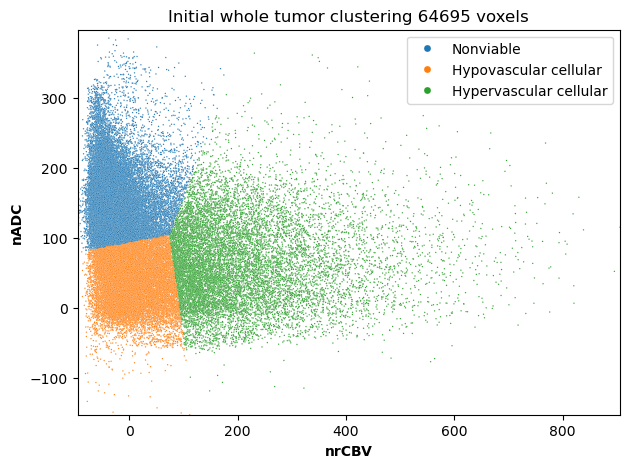

In [26]:
from matplotlib.font_manager import FontProperties
font_prop = FontProperties(family='Ubuntu', size=14, weight='bold')
row, col = 1, 1 
fig, ax = plt.subplots(nrows=row, ncols=col, figsize=(col*7, row*5))
plt.subplots_adjust(wspace=0.4, hspace=0.4)

xlim = (total_range['cbv_min'], total_range['cbv_max'])
ylim = (total_range['adc_min'], total_range['adc_max'])

subjs = ['initial']
titles = ['Initial', 'Recur']

for i, subj in enumerate(subjs):
    pre_to_plot = total[subj].copy()
    pre_to_plot['wt_kmeans_named'] = pre_to_plot['wt_kmeans'].map({0:'Nonviable', 
                                                                   1: 'Hypovascular cellular',
                                                                   2: 'Hypervascular cellular'})
    sns.scatterplot(
        data=pre_to_plot,
        x='cbv_normed',
        y='adc_normed',
        s=1,
        hue='wt_kmeans_named',
        hue_order=['Nonviable', 'Hypovascular cellular', 'Hypervascular cellular'],
        palette={'Nonviable':palette[0], 'Hypovascular cellular':palette[1], 'Hypervascular cellular':palette[2]},
        ax=ax
    ).set(xlim=xlim, ylim=ylim)
    ax.legend(markerscale=5)
    ax.set_title(f'{titles[i]} whole tumor clustering {len(pre_to_plot)} voxels')
    ax.set_xlabel('nrCBV', fontsize=10, fontweight='bold')
    ax.set_ylabel('nADC', fontsize=10, fontweight='bold')

plt.subplots_adjust(hspace=0.2, wspace=0.3) 
# plt.savefig(f"{root}/figures/Figure1_clustering.png", format="png", dpi=dpi, bbox_inches='tight')
plt.show()


/tmp/ipykernel_464399/2385273815.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('nipy_spectral')


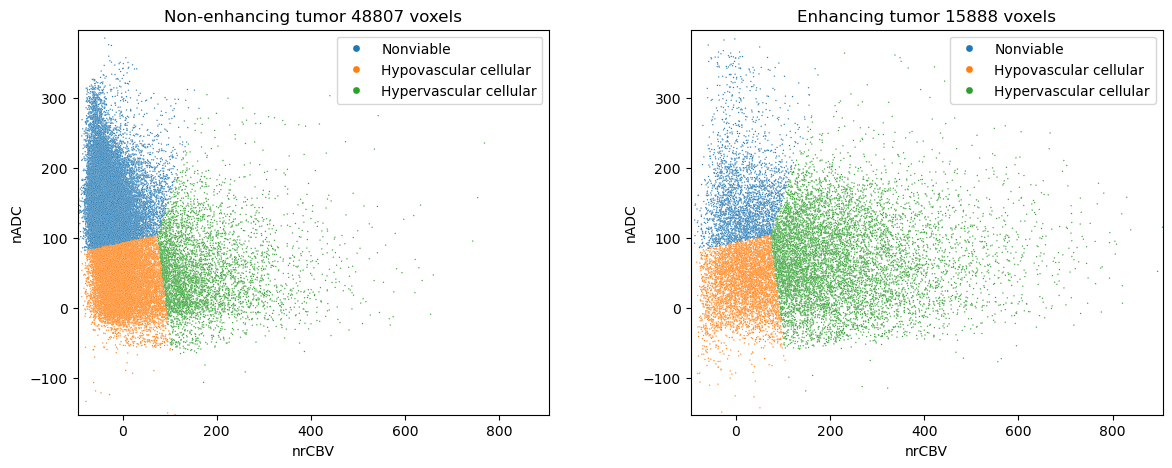

In [27]:
cmap = cm.get_cmap('nipy_spectral')  

row, col = 1, 2 
fig, ax = plt.subplots(nrows=row, ncols=col, figsize=(col*7, row*5))
plt.subplots_adjust(wspace=0.4, hspace=0.4)

xlim = (total_range['cbv_min'], total_range['cbv_max'])
ylim = (total_range['adc_min'], total_range['adc_max'])

subjs = [1, 0]
titles = ['Non-enhancing tumor', 'Enhancing tumor']

for i, subj in enumerate(subjs):
    pre_to_plot = total['initial'].loc[total['initial']['NE1CE0']==subj].copy() 
    pre_to_plot['wt_kmeans_named'] = pre_to_plot['wt_kmeans'].map({0:'Nonviable', 
                                                                   1: 'Hypovascular cellular',
                                                                   2: 'Hypervascular cellular'})
    sns.scatterplot(
        data=pre_to_plot,
        x='cbv_normed',
        y='adc_normed',
        s=1,
        hue='wt_kmeans_named',
        hue_order=['Nonviable', 'Hypovascular cellular', 'Hypervascular cellular'],
        palette={'Nonviable':palette[0], 'Hypovascular cellular':palette[1], 'Hypervascular cellular':palette[2]},
        ax=ax[i]
    ).set(title=f'{titles[i]} {len(pre_to_plot)} voxels', xlim=xlim, ylim=ylim)
    ax[i].legend(markerscale=5)
    ax[i].set_xlabel('nrCBV')
    ax[i].set_ylabel('nADC')

plt.subplots_adjust(hspace=0.2, wspace=0.3) 
plt.show()


In [28]:
pre_total = total['initial'].copy()
voxel_ratio = pd.DataFrame()
for subj in tqdm(sorted(original_meta.index)):

    rta = survival.loc[subj].RTA
    rta_cont = survival.loc[subj].RTA_cont
    ta1 = survival.loc[subj].TA1
    sex = survival.loc[subj].sex
    age = survival.loc[subj].age
    
    if sex == 'M':
        sex = 1
    else: # age == 'F':
        sex = 0

    if rta == 'D':
        increase=0
        decrease=1
    elif rta == 'I':
        increase=1
        decrease=0
    else: # if rta == 'S':
        increase=0
        decrease=0
        
    subj_df = pre_total[pre_total['subj']==subj]
    dictionary = {'RTA':rta, 'RTA_cont':rta_cont, 'TA1':ta1, 'increase':increase, 'decrease':decrease, 'Sex':sex, 'Age':age}
    for region in ['wt', 'ne', 'ce']:
        for cluster in range(n_cluster):
            if region == 'wt':
                dictionary[f'{region}_voxel_num'] = len(subj_df)
                dictionary[f'{region}_{cluster}_voxel_num'] = len(subj_df[subj_df['wt_kmeans'] == cluster])
                dictionary[f'{region}_{cluster}'] = dictionary[f'{region}_{cluster}_voxel_num']/dictionary[f'{region}_voxel_num']
            elif region == 'ne':
                dictionary[f'{region}_voxel_num'] = len(subj_df[subj_df['NE1CE0']==1])
                dictionary[f'{region}_{cluster}_voxel_num'] = len(subj_df[(subj_df['NE1CE0']==1)&(subj_df['wt_kmeans'] == cluster)])
                dictionary[f'{region}_{cluster}'] = dictionary[f'{region}_{cluster}_voxel_num']/dictionary[f'{region}_voxel_num']
            elif region == 'ce':
                dictionary[f'{region}_voxel_num'] = len(subj_df[subj_df['NE1CE0']==0])
                dictionary[f'{region}_{cluster}_voxel_num'] = len(subj_df[(subj_df['NE1CE0']==0)&(subj_df['wt_kmeans'] == cluster)])
                dictionary[f'{region}_{cluster}'] = dictionary[f'{region}_{cluster}_voxel_num']/dictionary[f'{region}_voxel_num']

    voxel_ratio = pd.concat([voxel_ratio, pd.DataFrame(dictionary, index=[int(subj)])], axis=0)


100%|██████████| 20/20 [00:00<00:00, 210.42it/s]


In [29]:
def calc_volume_ml(patient_dir): # study_dir
    try:
        ne = subprocess.run(["fslstats", f"{patient_dir}/NE_tumor_mask.nii.gz", "-V"], capture_output=True).stdout
        ne = float(ne.decode().split(' ')[1])/1000
    except Exception as e:
        print(patient_dir)
        print(e)
        ne=None

    try:
        et = subprocess.run(["fslstats", f"{patient_dir}/CE_tumor_mask.nii.gz", "-V"], capture_output=True).stdout
        et = float(et.decode().split(' ')[1])/1000
    except Exception as e:
        print(patient_dir)
        print(e)
        et=None

    try:
        wt = subprocess.run(["fslstats", f"{patient_dir}/WT_tumor_mask.nii.gz", "-V"], capture_output=True).stdout
        wt = float(wt.decode().split(' ')[1])/1000
    except Exception as e:
        print(patient_dir)
        print(e)
        wt=None

    try:
        brain = subprocess.run(["fslstats", f"{patient_dir}/t1ce_vox.nii.gz", "-l", "0", "-V"], capture_output=True).stdout
        brain = float(brain.decode().split(' ')[1])/1000
    except Exception as e:
        print(patient_dir)
        print(e)
        brain=None

    pid = patient_dir.split('/')[-2]
    return pd.DataFrame({'subj': pid,
                            'brain_volume': brain,
                            'wt_volume': wt,
                            'ce_volume': et, 
                            'ne_volume': ne, 
                            'study_path': patient_dir, 
                            }, index=[pid])



output = pd.DataFrame()
for sd in [f'{data_dir}/{pid}/1' for pid in survival.index]:
    df = calc_volume_ml(sd)
    output = pd.concat([output, df], axis=0)

output = output[['brain_volume', 'wt_volume', 'ce_volume', 'ne_volume']]

output.index = output.index.astype(int)
voxel_ratio = voxel_ratio.join(output, how='left')
voxel_ratio.index.name = 'ID'

display(voxel_ratio.reset_index(drop=True))

,RTA,RTA_cont,TA1,increase,decrease,Sex,Age,wt_voxel_num,wt_0_voxel_num,wt_0,...,ce_0_voxel_num,ce_0,ce_1_voxel_num,ce_1,ce_2_voxel_num,ce_2,brain_volume,wt_volume,ce_volume,ne_volume
0,I,12.1,12.5,1,0,1,60,5113,2616,0.511637,...,483,0.694964,142,0.204317,70,0.100719,1615.224,130.488,18.936,111.552
1,D,-35.0,35.0,0,1,0,49,1192,607,0.509228,...,66,0.379310,78,0.448276,30,0.172414,1645.680,30.768,4.248,26.520
2,D,-67.0,67.0,0,1,1,73,3178,1391,0.437697,...,195,0.156250,709,0.568109,344,0.275641,1457.400,87.816,34.080,53.736
3,D,-60.1,60.1,0,1,1,51,3084,1988,0.644617,...,345,0.291631,74,0.062553,764,0.645816,1619.736,78.336,29.400,48.936
4,I,2.4,0.0,1,0,0,41,2155,46,0.021346,...,15,0.018541,161,0.199011,633,0.782447,1483.680,52.872,19.848,33.024
5,D,-84.5,84.6,0,1,1,47,5187,3260,0.628494,...,434,0.271250,196,0.122500,970,0.606250,1723.464,132.240,42.696,89.544
6,S,0.0,0.0,0,0,1,24,3517,754,0.214387,...,263,0.187189,699,0.497509,443,0.315302,1701.672,94.392,39.264,55.128
7,I,10.1,0.0,1,0,0,63,4059,2591,0.638335,...,23,0.078767,13,0.044521,256,0.876712,1455.744,102.144,7.032,95.112
8,D,-17.4,32.2,0,1,1,65,1563,711,0.454894,...,20,0.094787,40,0.189573,151,0.715640,1482.144,38.472,5.112,33.360
9,I,50.2,19.5,1,0,0,74,4623,2867,0.620160,...,142,0.188079,93,0.123179,520,0.688742,1470.576,121.848,18.312,103.536


In [30]:
habitat_ratio = {}
habitat_ratio['initial'] = voxel_ratio.copy()

In [31]:
for op in ['initial']: 
    voxel_ratio = habitat_ratio[op].copy()
    for region in ['wt', 'ne', 'ce']:
        for cluster in range(n_cluster):
            voxel_ratio[f'{region}_{cluster}_volume'] = voxel_ratio[f'{region}_{cluster}'] * voxel_ratio[f'{region}_volume']
            voxel_ratio[f'{region}_{cluster}_adj'] = voxel_ratio[f'{region}_{cluster}_volume'] / voxel_ratio['brain_volume']
    habitat_ratio[op] = voxel_ratio.copy()

In [32]:
print('Univariable')
cph = CoxPHFitter()
voxel_ratio = habitat_ratio['initial'].copy()

for survival_target in ['PFS(W)', 'OS(W)']: 
    column = ['ne_1_volume'] 
    df = voxel_ratio[column] 
    df.index = df.index.astype(str)
    df = df.merge(original_meta[[survival_target, 'event_observed']], left_index=True, right_index=True)
    cph.fit(df, duration_col=survival_target, event_col='event_observed')
    df['partial_hazard'] = cph.predict_partial_hazard(df)
    c_index = concordance_index(df[survival_target], -df['partial_hazard'], df['event_observed'])
    print(f'{survival_target} C-index: {c_index:.4f}')
    for c in column:
        print(f'{c} p-val: {cph.summary["p"][c]}, HR ratio: {cph.summary["exp(coef)"][c]}')


Univariable
PFS(W) C-index: 0.6316
ne_1_volume p-val: 0.04593123333638482, HR ratio: 1.0458618573310572
OS(W) C-index: 0.5026
ne_1_volume p-val: 0.9342331122804969, HR ratio: 1.0020599823606546


In [33]:
for region in ['ne']:
    for cluster in [1]:
        for data in [f'{region}_{cluster}_volume']:
            for survival_target in ['PFS(W)', 'OS(W)']: 
                column = [data] 
                df = voxel_ratio[column] 
                df.index = df.index.astype(str)
                df = df.merge(original_meta[[survival_target, 'event_observed']], left_index=True, right_index=True)
                cph.fit(df, duration_col=survival_target, event_col='event_observed')
                df['partial_hazard'] = cph.predict_partial_hazard(df)
                c_index = concordance_index(df[survival_target], -df['partial_hazard'], df['event_observed'])
                print(f'{survival_target} C-index: {c_index:.4f}')
                for c in column:
                    p_val = cph.summary["p"][c]
                    if p_val < 0.05:
                        print(f'{c} p-val: {p_val}, HR ratio: {cph.summary["exp(coef)"][c]}')
            print()

PFS(W) C-index: 0.6316
ne_1_volume p-val: 0.04593123333638482, HR ratio: 1.0458618573310572
OS(W) C-index: 0.5026



In [34]:
print('\nMultivariable1')
cph = CoxPHFitter()
voxel_ratio = habitat_ratio['initial'].copy()
for survival_target in ['PFS(W)', 'OS(W)']: 
    column = ['ne_1_volume', 'TA1']
    df = voxel_ratio[column] 
    df.index = df.index.astype(str)
    df = df.merge(original_meta[[survival_target, 'event_observed']], left_index=True, right_index=True)
    cph.fit(df, duration_col=survival_target, event_col='event_observed')
    df['partial_hazard'] = cph.predict_partial_hazard(df)
    c_index = concordance_index(df[survival_target], -df['partial_hazard'], df['event_observed'])
    print(f'{survival_target} C-index: {c_index:.4f}')
    for c in column:
        print(f'{c} p-val: {cph.summary["p"][c]}, HR ratio: {cph.summary["exp(coef)"][c]}')



Multivariable1
PFS(W) C-index: 0.7000
ne_1_volume p-val: 0.010018819197879853, HR ratio: 1.0658665660079045
TA1 p-val: 0.038187484436340215, HR ratio: 1.0096911704847085
OS(W) C-index: 0.6508
ne_1_volume p-val: 0.498657448015449, HR ratio: 1.0177253550172727
TA1 p-val: 0.08785520825757814, HR ratio: 1.0071399535965124


In [35]:
print('\nMultivariate1')
cph = CoxPHFitter()
voxel_ratio = habitat_ratio['initial'].copy()
voxel_ratio.index = voxel_ratio.index.astype(str)
voxel_ratio = voxel_ratio.join(original_meta[['MGMTp']], how='left')
for survival_target in ['PFS(W)', 'OS(W)']:
    column = ['ne_1_volume', 'MGMTp'] 
    df = voxel_ratio[column] 
    df.index = df.index.astype(str)
    df = df.merge(original_meta[[survival_target, 'event_observed']], left_index=True, right_index=True)
    cph.fit(df, duration_col=survival_target, event_col='event_observed')
    df['partial_hazard'] = cph.predict_partial_hazard(df)
    c_index = concordance_index(df[survival_target], -df['partial_hazard'], df['event_observed'])
    print(f'{survival_target} C-index: {c_index:.4f}')
    for c in column:
        print(f'{c} p-val: {cph.summary["p"][c]}, HR ratio: {cph.summary["exp(coef)"][c]}')


Multivariate1
PFS(W) C-index: 0.6632
ne_1_volume p-val: 0.3543171026230225, HR ratio: 1.0254474826158781
MGMTp p-val: 0.15440995375632563, HR ratio: 0.39471863988293343
OS(W) C-index: 0.7619
ne_1_volume p-val: 0.21718860245972957, HR ratio: 0.9626529286851522
MGMTp p-val: 0.0029268223925674997, HR ratio: 0.12291368084247319


In [36]:
print('\nMultivariate1')
cph = CoxPHFitter()
voxel_ratio = habitat_ratio['initial'].copy()
voxel_ratio.index = voxel_ratio.index.astype(str)
voxel_ratio = voxel_ratio.join(original_meta[['TERTp']], how='left')
for survival_target in ['PFS(W)', 'OS(W)']: 
    column = ['ne_1_volume', 'TERTp'] 
    df = voxel_ratio[column] 
    df.index = df.index.astype(str)
    df = df.merge(original_meta[[survival_target, 'event_observed']], left_index=True, right_index=True)
    cph.fit(df, duration_col=survival_target, event_col='event_observed')
    df['partial_hazard'] = cph.predict_partial_hazard(df)
    c_index = concordance_index(df[survival_target], -df['partial_hazard'], df['event_observed'])
    print(f'{survival_target} C-index: {c_index:.4f}')
    for c in column:
        print(f'{c} p-val: {cph.summary["p"][c]}, HR ratio: {cph.summary["exp(coef)"][c]}')


Multivariate1
PFS(W) C-index: 0.6684
ne_1_volume p-val: 0.033201653307866966, HR ratio: 1.0482935008734873
TERTp p-val: 0.5955466260327598, HR ratio: 1.3040080450856602
OS(W) C-index: 0.7196
ne_1_volume p-val: 0.4545875127410778, HR ratio: 1.0145533581527226
TERTp p-val: 0.007968857427885808, HR ratio: 6.104144867924594


In [37]:
voxel_ratio = habitat_ratio['initial'].copy()
voxel_ratio.index = voxel_ratio.index.astype(str)
voxel_ratio = voxel_ratio.merge(survival[['high_TA1', 'OP1']], left_index=True, right_index=True)
treshold = 0.05

In [38]:
target = 'high_TA1'
y = voxel_ratio[target]
print('===========================================================================')
print(target)
print(f'number of {target}: ', len(voxel_ratio.loc[voxel_ratio[target]==1]))
print(f'number of non-{target}: ', len(voxel_ratio.loc[voxel_ratio[target]==0]))
print('===========================================================================')
p_list = []
for region in ['wt', 'ne', 'ce']:
    print(f'{region}_volume')
    X = voxel_ratio[[f'{region}_volume']]  
    low = voxel_ratio.loc[voxel_ratio[target]==1, f'{region}_volume']
    high = voxel_ratio.loc[voxel_ratio[target]==0, f'{region}_volume']
    mann_u, mann_p = mannwhitneyu(low, high)
    if mann_p < treshold:
        print(f'    mann_u: {mann_u}, mann_p: {mann_p}')
        print(f'{target} mean', low.mean(), f'non-{target} mean', high.mean())
        X = sm.add_constant(X)
        logit_model = sm.Logit(y, X)
        result = logit_model.fit()
        y_pred_prob = result.predict(X)
        auc = roc_auc_score(y, y_pred_prob)
        print('AUC', round(auc, 3))
        print()
    for cluster in range(n_cluster): 
        for data in [f'{region}_{cluster}_volume']: 
            print(data)
            X = voxel_ratio[[data]]  
            low = voxel_ratio.loc[voxel_ratio[target]==1, data]
            high = voxel_ratio.loc[voxel_ratio[target]==0, data]
            mann_u, mann_p = mannwhitneyu(low, high)
            p_list.append(mann_p)
            if mann_p < treshold:
                print(f'    mann_u: {mann_u}, mann_p: {mann_p}')
                print(f'{target} mean', low.mean(), f'non-{target} mean', high.mean())
                X = sm.add_constant(X)
                logit_model = sm.Logit(y, X)
                result = logit_model.fit()
                y_pred_prob = result.predict(X)
                intercept = result.params[0]  # const
                coef = result.params[1]       # feature
                cutoff_x = -intercept / coef 
                auc = roc_auc_score(y, y_pred_prob)
                print('AUC', round(auc, 3), "decision boundary: ", round(cutoff_x, 3))
                print()

high_TA1
number of high_TA1:  8
number of non-high_TA1:  12
wt_volume
wt_0_volume
wt_1_volume
wt_2_volume
ne_volume
ne_0_volume
ne_1_volume
ne_2_volume
ce_volume
ce_0_volume
ce_1_volume
ce_2_volume
    mann_u: 77.0, mann_p: 0.02524410573946178
high_TA1 mean 14.616876419389278 non-high_TA1 mean 7.828745666509799
Optimization terminated successfully.
         Current function value: 0.538283
         Iterations 6
AUC 0.802 decision boundary:  13.213



/tmp/ipykernel_464399/323354528.py:40: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  intercept = result.params[0]  # const
/tmp/ipykernel_464399/323354528.py:41: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coef = result.params[1]       # feature


In [39]:

target = 'decrease'
y = voxel_ratio[target]
print('===========================================================================')
print(target)
print(f'number of {target}: ', len(voxel_ratio.loc[voxel_ratio[target]==1]))
print(f'number of non-{target}: ', len(voxel_ratio.loc[voxel_ratio[target]==0]))
print('===========================================================================')
p_list = []
for region in ['wt', 'ne', 'ce']:
    print(f'{region}_volume')
    X = voxel_ratio[[f'{region}_volume']]  # 독립변수 # 
    low = voxel_ratio.loc[voxel_ratio[target]==1, f'{region}_volume']
    high = voxel_ratio.loc[voxel_ratio[target]==0, f'{region}_volume']
    mann_u, mann_p = mannwhitneyu(low, high)
    if mann_p < treshold:
        print(f'    mann_u: {mann_u}, mann_p: {mann_p}')
        print(f'{target} mean', low.mean(), f'non-{target} mean', high.mean())
        X = sm.add_constant(X)
        logit_model = sm.Logit(y, X)
        result = logit_model.fit()
        y_pred_prob = result.predict(X)
        auc = roc_auc_score(y, y_pred_prob)
        print('AUC', round(auc, 3))
        print()
    for cluster in range(n_cluster): 
        for data in [f'{region}_{cluster}_volume']: 
            print(data)
            X = voxel_ratio[[data]]
            low = voxel_ratio.loc[voxel_ratio[target]==1, data]
            high = voxel_ratio.loc[voxel_ratio[target]==0, data]
            mann_u, mann_p = mannwhitneyu(low, high)
            p_list.append(mann_p)
            if mann_p < treshold:
                print(f'    mann_u: {mann_u}, mann_p: {mann_p}')
                print(f'{target} mean', low.mean(), f'non-{target} mean', high.mean())
                X = sm.add_constant(X)
                logit_model = sm.Logit(y, X)
                result = logit_model.fit()
                y_pred_prob = result.predict(X)
                intercept = result.params[0]  # const
                coef = result.params[1]       # feature
                cutoff_x = -intercept / coef 
                auc = roc_auc_score(y, y_pred_prob)
                fpr, tpr, thresholds = roc_curve(y, y_pred_prob)
                print('AUC', round(auc, 3), "decision boundary: ", round(cutoff_x, 3))
                print()

decrease
number of decrease:  12
number of non-decrease:  8
wt_volume
wt_0_volume
wt_1_volume
wt_2_volume
ne_volume
ne_0_volume
ne_1_volume
    mann_u: 18.0, mann_p: 0.020131777407319206
decrease mean 15.993860730655719 non-decrease mean 27.197121176772445
Optimization terminated successfully.
         Current function value: 0.473413
         Iterations 7
AUC 0.812 decision boundary:  22.775

ne_2_volume
ce_volume
ce_0_volume
ce_1_volume
ce_2_volume


/tmp/ipykernel_464399/1772380061.py:40: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  intercept = result.params[0]  # const
/tmp/ipykernel_464399/1772380061.py:41: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coef = result.params[1]       # feature


100%|██████████| 20/20 [00:00<00:00, 21.53it/s]


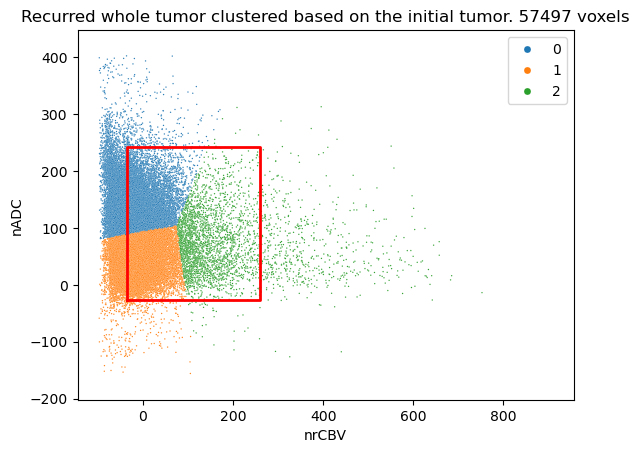

In [40]:

pre_total = pd.DataFrame()
for subj in tqdm(sorted(original_meta.index)):
    directory = os.path.join(data_dir, subj, '2')
    if not os.path.isdir(directory): continue

    df = pd.DataFrame()
    for file_name, name in zip(['flair_vox.nii.gz', 'rCBV_vox.nii.gz', 'adc_vox.nii.gz', 't1ce_vox.nii.gz', 
                                'flair_rad.nii.gz', 'rCBV_rad.nii.gz', 'adc_rad.nii.gz', 't1ce_rad.nii.gz', 
                                ], 
                         ['flair', 'cbv', 'adc', 't1ce', 
                          'flair_normed', 'cbv_normed', 'adc_normed', 't1ce_normed', 
                          ]):
        img = ants.image_read(os.path.join(directory, file_name))
        img = img.numpy()
        img = img.flatten()
        df = pd.concat([df, pd.DataFrame({name:img})], axis=1)

    for file_name, name in zip(['NE_tumor_mask.nii.gz', 'CE_tumor_mask.nii.gz'], ['NE', 'CE']):
        img = ants.image_read(os.path.join(directory, file_name))
        img = img.numpy()
        img = img.flatten()
        img = pd.Series(img)
        img = img[img>0].index
        df[name] = None
        df.loc[img, name] = img

    df = df[(~pd.isnull(df['NE'])) | (~pd.isnull(df['CE']))]
    df['subj'] = subj
    df['flair_adc'] = (df['flair_normed']+10000) / (df['adc_normed']+10000)
    df['cbv_adc'] = (df['cbv_normed']+10000) / (df['adc_normed']+10000)

    pre_total = pd.concat([pre_total, df], axis=0)
    
pre_total['NE1CE0'] = pre_total.apply(lambda row: 1 if row['NE'] is not None else 0, axis=1)
# leave only valid voxels
pre_total = pre_total[(pre_total['adc']>0)&(pre_total['cbv']>0)&(pre_total['flair']>0)&(pre_total['t1ce']>0)]
# 99.9 percentile as outliers
percentiles = pre_total[['adc', 'cbv', 'flair', 't1ce', 'flair_adc', 'cbv_adc']].quantile(0.999)
# remove outlier
pre_total = pre_total[
    (pre_total['adc'] <= percentiles['adc']) &
    (pre_total['cbv'] <= percentiles['cbv']) &
    (pre_total['flair'] <= percentiles['flair']) &
    (pre_total['t1ce'] <= percentiles['t1ce']) # &
]

pre_total['wt_kmeans'] = kmeans.predict(pre_total[['cbv_normed', 'adc_normed']])
sns.scatterplot(data=pre_total, x='cbv_normed', y='adc_normed', hue='wt_kmeans', s=1, palette=palette)
plt.title(f'Recurred whole tumor clustered based on the initial tumor. {len(pre_total)} voxels')
plt.xlabel('nrCBV')
plt.ylabel('nADC')
plt.legend(markerscale=5)
plt.plot([common_range['cbv_min'], common_range['cbv_min'], common_range['cbv_max'], common_range['cbv_max'], common_range['cbv_min']], 
         [common_range['adc_min'], common_range['adc_max'], common_range['adc_max'], common_range['adc_min'], common_range['adc_min']], 
         'r-', 
         linewidth=2)
plt.xlim(total_range['cbv_min']-50, total_range['cbv_max']+50)
plt.ylim(total_range['adc_min']-50, total_range['adc_max']+50)

total['recur'] = pre_total.copy()

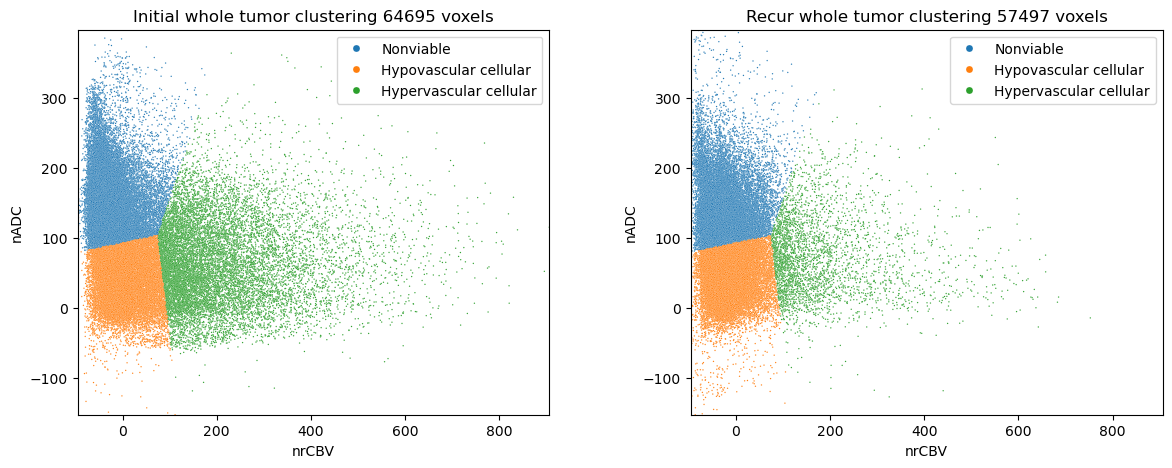

In [41]:
row, col = 1, 2  
fig, ax = plt.subplots(nrows=row, ncols=col, figsize=(col*7, row*5))
plt.subplots_adjust(wspace=0.4, hspace=0.4)

xlim = (total_range['cbv_min'], total_range['cbv_max'])
ylim = (total_range['adc_min'], total_range['adc_max'])

subjs = ['initial', 'recur']
titles = ['Initial', 'Recur']

for i, subj in enumerate(subjs):
    pre_to_plot = total[subj].copy()
    pre_to_plot['wt_kmeans_named'] = pre_to_plot['wt_kmeans'].map({0:'Nonviable', 
                                                                   1: 'Hypovascular cellular',
                                                                   2: 'Hypervascular cellular'})
    sns.scatterplot(
        data=pre_to_plot,
        x='cbv_normed',
        y='adc_normed',
        s=1,
        hue='wt_kmeans_named',
        hue_order=['Nonviable', 'Hypovascular cellular', 'Hypervascular cellular'],
        palette={'Nonviable':palette[0], 'Hypovascular cellular':palette[1], 'Hypervascular cellular':palette[2]},
        ax=ax[i]
    ).set(title=f'{titles[i]} whole tumor clustering {len(pre_to_plot)} voxels', xlim=xlim, ylim=ylim)
    ax[i].legend(markerscale=5)
    ax[i].set_xlabel('nrCBV')
    ax[i].set_ylabel('nADC')

plt.subplots_adjust(hspace=0.2, wspace=0.3) 
plt.show()


In [42]:
pre_total = total['recur'].copy()

voxel_ratio = pd.DataFrame()

for subj in tqdm(sorted(original_meta.index)):
    directory = os.path.join(data_dir, subj, '2')
    if not os.path.isdir(directory): continue

    rta = survival.loc[subj].RTA
    rta_cont = survival.loc[subj].RTA_cont
    ta1 = survival.loc[subj].TA1
    sex = survival.loc[subj].sex
    age = survival.loc[subj].age
    
    if sex == 'M':
        sex = 1
    else: # age == 'F':
        sex = 0

    if rta == 'D':
        increase=0
        decrease=1
    elif rta == 'I':
        increase=1
        decrease=0
    else: # if rta == 'S':
        increase=0
        decrease=0

    subj_df = pre_total[pre_total['subj']==subj].copy() 

    dictionary = {'RTA':rta, 'RTA_cont':rta_cont, 'TA1':ta1, 'increase':increase, 'decrease':decrease, 'Sex':sex, 'Age':age}
    for region in ['wt', 'ne', 'ce']:
        for cluster in range(n_cluster):
            if region == 'wt':
                dictionary[f'{region}_voxel_num'] = len(subj_df)
                dictionary[f'{region}_{cluster}_voxel_num'] = len(subj_df[subj_df['wt_kmeans'] == cluster])
                dictionary[f'{region}_{cluster}'] = dictionary[f'{region}_{cluster}_voxel_num']/dictionary[f'{region}_voxel_num']
            elif region == 'ne':
                dictionary[f'{region}_voxel_num'] = len(subj_df[subj_df['NE1CE0']==1])
                dictionary[f'{region}_{cluster}_voxel_num'] = len(subj_df[(subj_df['NE1CE0']==1)&(subj_df['wt_kmeans'] == cluster)])
                dictionary[f'{region}_{cluster}'] = dictionary[f'{region}_{cluster}_voxel_num']/dictionary[f'{region}_voxel_num']
            elif region == 'ce':
                dictionary[f'{region}_voxel_num'] = len(subj_df[subj_df['NE1CE0']==0])
                dictionary[f'{region}_{cluster}_voxel_num'] = len(subj_df[(subj_df['NE1CE0']==0)&(subj_df['wt_kmeans'] == cluster)])
                dictionary[f'{region}_{cluster}'] = dictionary[f'{region}_{cluster}_voxel_num']/dictionary[f'{region}_voxel_num']

    voxel_ratio = pd.concat([voxel_ratio, pd.DataFrame(dictionary, index=[int(subj)])], axis=0)

output = pd.DataFrame()
for sd in [f'{data_dir}/{pid}/2' for pid in survival.index]:
    df = calc_volume_ml(sd)
    output = pd.concat([output, df], axis=0)

output = output[['brain_volume', 'wt_volume', 'ce_volume', 'ne_volume']]

output.index = output.index.astype(int)
voxel_ratio = voxel_ratio.join(output, how='left')
voxel_ratio.index.name = 'ID'
habitat_ratio['recur'] = voxel_ratio.copy()

display(voxel_ratio.reset_index(drop=True))

100%|██████████| 20/20 [00:00<00:00, 223.96it/s]


/media/data/syjeong/GBM_RTA/data/only_initial/43588514/2
list index out of range
/media/data/syjeong/GBM_RTA/data/only_initial/43588514/2
list index out of range
/media/data/syjeong/GBM_RTA/data/only_initial/43588514/2
list index out of range
/media/data/syjeong/GBM_RTA/data/only_initial/43588514/2
list index out of range


/tmp/ipykernel_464399/737388868.py:53: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  output = pd.concat([output, df], axis=0)


,RTA,RTA_cont,TA1,increase,decrease,Sex,Age,wt_voxel_num,wt_0_voxel_num,wt_0,...,ce_0_voxel_num,ce_0,ce_1_voxel_num,ce_1,ce_2_voxel_num,ce_2,brain_volume,wt_volume,ce_volume,ne_volume
0,I,12.1,12.5,1,0,1,60,2827,289,0.102229,...,9,0.123288,54,0.739726,10,0.136986,1631.256,72.912,1.848,71.064
1,D,-35.0,35.0,0,1,0,49,2351,1280,0.544449,...,127,0.415033,111,0.362745,68,0.222222,1653.216,60.288,7.392,52.896
2,D,-67.0,67.0,0,1,1,73,10472,5175,0.494175,...,1628,0.746104,409,0.187443,145,0.066453,1745.592,270.072,56.784,213.288
3,D,-60.1,60.1,0,1,1,51,549,91,0.165756,...,47,0.643836,23,0.315068,3,0.041096,1589.928,13.608,2.064,11.544
4,I,2.4,0.0,1,0,0,41,1076,174,0.161710,...,24,0.352941,27,0.397059,17,0.250000,1443.552,27.720,1.920,25.800
5,D,-84.5,84.6,0,1,1,47,1249,741,0.593275,...,73,0.356098,27,0.131707,105,0.512195,1681.536,33.576,6.144,27.432
6,S,0.0,0.0,0,0,1,24,914,246,0.269147,...,174,0.478022,141,0.387363,49,0.134615,1656.408,29.184,14.664,14.520
7,I,10.1,0.0,1,0,0,63,2030,592,0.291626,...,15,0.075758,60,0.303030,123,0.621212,1438.296,53.976,4.968,49.008
8,I,50.2,19.5,1,0,0,74,1548,267,0.172481,...,30,0.326087,31,0.336957,31,0.336957,1408.896,37.752,2.664,35.088
9,D,-205.0,244.7,0,1,0,42,5322,3797,0.713454,...,911,0.607333,333,0.222000,256,0.170667,1506.600,136.464,41.736,94.728


In [43]:
for op in ['initial', 'recur']:
    voxel_ratio = habitat_ratio[op].copy()
    for region in ['wt', 'ne', 'ce']:
        for cluster in range(n_cluster):
            voxel_ratio[f'{region}_{cluster}_volume'] = voxel_ratio[f'{region}_{cluster}'] * voxel_ratio[f'{region}_volume']
            voxel_ratio[f'{region}_{cluster}_adj'] = voxel_ratio[f'{region}_{cluster}_volume'] / voxel_ratio['brain_volume']
    habitat_ratio[op] = voxel_ratio.copy()



voxel_ratio = habitat_ratio['initial'].copy()
for region in ['wt', 'ne', 'ce']:
    for cluster in range(n_cluster):
        for data in [f'{region}_{cluster}', f'{region}_{cluster}_voxel_num', f'{region}_{cluster}_volume', f'{region}_volume', f'{region}_{cluster}_adj']:
            voxel_ratio[data] = habitat_ratio['recur'][data] - habitat_ratio['initial'][data]
voxel_ratio['brain_volume'] = habitat_ratio['recur']['brain_volume'] - habitat_ratio['initial']['brain_volume']
habitat_ratio['delta'] = voxel_ratio.copy()

In [44]:
display(habitat_ratio['delta'].reset_index(drop=True))

,RTA,RTA_cont,TA1,increase,decrease,Sex,Age,wt_voxel_num,wt_0_voxel_num,wt_0,...,ne_1_volume,ne_1_adj,ne_2_volume,ne_2_adj,ce_0_volume,ce_0_adj,ce_1_volume,ce_1_adj,ce_2_volume,ce_2_adj
0,I,12.1,12.5,1,0,1,60,5113,-2327.0,-0.409408,...,6.450049,0.003625,-0.306104,-0.000210,-12.932003,-0.008008,-2.501924,-0.001557,-1.654072,-0.001026
1,D,-35.0,35.0,0,1,0,49,1192,673.0,0.035221,...,8.638749,0.005195,2.007371,0.001210,1.456611,0.000877,0.777136,0.000465,0.910253,0.000549
2,D,-67.0,67.0,0,1,1,73,3178,3784.0,0.056478,...,98.361607,0.054087,3.231560,0.001798,37.041797,0.020617,-8.717407,-0.007187,-5.620391,-0.004284
3,D,-60.1,60.1,0,1,1,51,3084,-1897.0,-0.478861,...,6.692388,0.004248,-2.856979,-0.001759,-7.245088,-0.004458,-1.188752,-0.000726,-18.902160,-0.011669
4,I,2.4,0.0,1,0,0,41,2155,128.0,0.140364,...,0.749821,0.000911,-11.052524,-0.007444,0.309637,0.000221,-3.187620,-0.002134,-15.050017,-0.010135
5,D,-84.5,84.6,0,1,1,47,5187,-2519.0,-0.035220,...,-9.054320,-0.005136,-0.063164,-0.000012,-9.393427,-0.005419,-4.421050,-0.002554,-22.737523,-0.013147
6,S,0.0,0.0,0,0,1,24,3517,-508.0,0.054759,...,-15.831482,-0.009137,-13.861102,-0.008110,-0.340059,-0.000087,-13.853904,-0.008050,-10.406037,-0.006083
7,I,10.1,0.0,1,0,0,63,4059,-1999.0,-0.346709,...,9.130967,0.006541,-5.831585,-0.003995,-0.177527,-0.000119,1.192386,0.000832,-3.078859,-0.002089
8,D,-17.4,32.2,0,1,1,65,1563,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,I,50.2,19.5,1,0,0,74,4623,-2600.0,-0.447679,...,1.153047,0.001654,-2.371535,-0.001608,-2.575416,-0.001725,-1.357998,-0.000897,-11.714586,-0.007939


In [45]:
voxel_ratio = habitat_ratio['delta'].dropna()
display(voxel_ratio.reset_index(drop=True))

,RTA,RTA_cont,TA1,increase,decrease,Sex,Age,wt_voxel_num,wt_0_voxel_num,wt_0,...,ne_1_volume,ne_1_adj,ne_2_volume,ne_2_adj,ce_0_volume,ce_0_adj,ce_1_volume,ce_1_adj,ce_2_volume,ce_2_adj
0,I,12.1,12.5,1,0,1,60,5113,-2327.0,-0.409408,...,6.450049,0.003625,-0.306104,-0.000210,-12.932003,-0.008008,-2.501924,-0.001557,-1.654072,-0.001026
1,D,-35.0,35.0,0,1,0,49,1192,673.0,0.035221,...,8.638749,0.005195,2.007371,0.001210,1.456611,0.000877,0.777136,0.000465,0.910253,0.000549
2,D,-67.0,67.0,0,1,1,73,3178,3784.0,0.056478,...,98.361607,0.054087,3.231560,0.001798,37.041797,0.020617,-8.717407,-0.007187,-5.620391,-0.004284
3,D,-60.1,60.1,0,1,1,51,3084,-1897.0,-0.478861,...,6.692388,0.004248,-2.856979,-0.001759,-7.245088,-0.004458,-1.188752,-0.000726,-18.902160,-0.011669
4,I,2.4,0.0,1,0,0,41,2155,128.0,0.140364,...,0.749821,0.000911,-11.052524,-0.007444,0.309637,0.000221,-3.187620,-0.002134,-15.050017,-0.010135
5,D,-84.5,84.6,0,1,1,47,5187,-2519.0,-0.035220,...,-9.054320,-0.005136,-0.063164,-0.000012,-9.393427,-0.005419,-4.421050,-0.002554,-22.737523,-0.013147
6,S,0.0,0.0,0,0,1,24,3517,-508.0,0.054759,...,-15.831482,-0.009137,-13.861102,-0.008110,-0.340059,-0.000087,-13.853904,-0.008050,-10.406037,-0.006083
7,I,10.1,0.0,1,0,0,63,4059,-1999.0,-0.346709,...,9.130967,0.006541,-5.831585,-0.003995,-0.177527,-0.000119,1.192386,0.000832,-3.078859,-0.002089
8,I,50.2,19.5,1,0,0,74,4623,-2600.0,-0.447679,...,1.153047,0.001654,-2.371535,-0.001608,-2.575416,-0.001725,-1.357998,-0.000897,-11.714586,-0.007939
9,D,-205.0,244.7,0,1,0,42,2828,1907.0,0.045137,...,9.709748,0.006392,1.788852,0.001172,23.751709,0.015756,5.599682,0.003696,-1.031391,-0.000732


In [46]:
print('spearmanr', spearmanr(voxel_ratio['ne_1_volume'], voxel_ratio['ne_volume'])) 

spearmanr SignificanceResult(statistic=0.7719298245614035, pvalue=0.00010807079839875924)


In [47]:
print('spearmanr', spearmanr(voxel_ratio['ne_1_volume'], voxel_ratio['ce_volume'])) 

spearmanr SignificanceResult(statistic=0.5912280701754385, pvalue=0.007676472592226471)


In [48]:
print('spearmanr', spearmanr(voxel_ratio['ce_1_volume'], voxel_ratio['ce_volume']))

spearmanr SignificanceResult(statistic=0.7456140350877193, pvalue=0.0002479007969023676)


In [49]:
print('spearmanr', spearmanr(voxel_ratio['ce_2_volume'], voxel_ratio['ce_volume']))

spearmanr SignificanceResult(statistic=0.8035087719298245, pvalue=3.419322763877887e-05)


In [50]:
print('spearmanr', spearmanr(voxel_ratio['ce_0_volume'], voxel_ratio['ce_volume']))

spearmanr SignificanceResult(statistic=0.8473684210526315, pvalue=4.681087721120231e-06)


In [51]:
print('spearmanr', spearmanr(voxel_ratio['ce_2_volume'], voxel_ratio['ne_volume']))

spearmanr SignificanceResult(statistic=0.42105263157894735, pvalue=0.07261203928039694)


In [52]:
print('spearmanr', spearmanr(voxel_ratio['ce_0_volume'], voxel_ratio['ne_volume']))

spearmanr SignificanceResult(statistic=0.6982456140350877, pvalue=0.0008846991322268252)


In [53]:
print('spearmanr', spearmanr(voxel_ratio['ne_0_volume'], voxel_ratio['ce_volume'])) 

spearmanr SignificanceResult(statistic=0.556140350877193, pvalue=0.013410683382539602)


# Radiomics Analysis

In [ ]:
# change settings here
rad_root = f"{root}/excel_csv/radiomics_samespacing_2-2-6_new_bin5_initial_GTR" # the directory where radiomics data directories are located 
mask_type_list = ['NE', 'CE', 'WT']
modal_dir = {'ADC':'ADC_radiomics', 
            'CBV':'CBV_radiomics', 
            'T1CE':'T1CE_radiomics', 
            'FLAIR':'FLAIR_radiomics'}
sub_dirs = {'pre':'1'} 
radiomics = pd.DataFrame()

for mask_type in mask_type_list:
    shape_feature={'pre':None, 'post':None}
    for modal, directory in modal_dir.items():
        df={}
        for op, sub in sub_dirs.items():
            df[op] = f'{mask_type}2{modal}_{sub}_radiomics.csv'
            df[op] = pd.read_csv(os.path.join(rad_root, directory, sub, df[op]))
            df[op].set_index('subj', inplace=True) 
            if shape_feature[op] is None:
                shape_columns = list(filter(lambda col: col.startswith('original_shape_'), df[op].columns))
                shape_feature[op] = df[op][shape_columns]
            df[op] = df[op].drop(shape_columns, axis=1)
        df['pre'] = df['pre'].add_prefix(f'{mask_type}_{modal.lower()}_initial_')
        radiomics = pd.concat([radiomics, df['pre']], axis=1)
    shape_feature['pre'] = shape_feature['pre'].add_prefix(f'{mask_type}_shape_initial_')
    radiomics = pd.concat([radiomics, shape_feature['pre']], axis=1)

columns = radiomics.columns
columns

Index(['NE_adc_initial_original_firstorder_10Percentile',
       'NE_adc_initial_original_firstorder_90Percentile',
       'NE_adc_initial_original_firstorder_Energy',
       'NE_adc_initial_original_firstorder_Entropy',
       'NE_adc_initial_original_firstorder_InterquartileRange',
       'NE_adc_initial_original_firstorder_Kurtosis',
       'NE_adc_initial_original_firstorder_Maximum',
       'NE_adc_initial_original_firstorder_MeanAbsoluteDeviation',
       'NE_adc_initial_original_firstorder_Mean',
       'NE_adc_initial_original_firstorder_Median',
       ...
       'WT_shape_initial_original_shape_Maximum2DDiameterColumn',
       'WT_shape_initial_original_shape_Maximum2DDiameterRow',
       'WT_shape_initial_original_shape_Maximum2DDiameterSlice',
       'WT_shape_initial_original_shape_Maximum3DDiameter',
       'WT_shape_initial_original_shape_MeshVolume',
       'WT_shape_initial_original_shape_MinorAxisLength',
       'WT_shape_initial_original_shape_Sphericity',
       'WT

In [55]:
radiomics.index = radiomics.index.astype(str)
radiomics = original_meta.join(radiomics, how='left')

In [56]:
radiomics_null_df = radiomics.isnull().sum().reset_index()
radiomics_null_df.columns = ['Feature', 'Null_Count']
radiomics_null_df['Null_Count'].sum()

1

In [57]:
radiomics_null_df

,Feature,Null_Count
0,sex,0
1,age,0
2,TA1,0
3,TA2,0
4,RTA,0
...,...,...
24610,WT_shape_initial_original_shape_MinorAxisLength,0
24611,WT_shape_initial_original_shape_Sphericity,0
24612,WT_shape_initial_original_shape_SurfaceArea,0
24613,WT_shape_initial_original_shape_SurfaceVolumeR...,0


In [58]:
rad_pvals = {}

In [59]:
p_val_df = pd.DataFrame()
for col in columns: 
    if radiomics[col].nunique() == 1: 
        print('only one straight value', col)
        continue
    if radiomics[col].isna().sum() != 0: 
        print('there are NaN values', col)
        continue
    if np.isinf(radiomics[col]).sum() != 0: 
        print('there are infinite values', col)
        continue

    y = radiomics['TA1']
    spearman_rho, spearman_p = spearmanr(y, radiomics[col])
    kendall_tau, kendall_p = kendalltau(y, radiomics[col])
    mann_u, mann_p = mannwhitneyu(radiomics.loc[radiomics['TA1']>35, col], radiomics.loc[radiomics['TA1']<=35, col])
    name = col.split('_')
    p_val_df = pd.concat([p_val_df, pd.DataFrame({'region':name[0],
                                                'modal':name[1],
                                                'op':name[2],
                                                'filter':name[3],
                                                'Parent':name[4],
                                                'feature':'_'.join(name[5:]),
                                                'spearman_rho':spearman_rho, 
                                                'spearman_p':spearman_p, 
                                                'kendall_tau':kendall_tau, 
                                                'kendall_p':kendall_p, 
                                                'mann_u':mann_u, 
                                                'mann_p':mann_p, 
                                                }, index=[col])], axis=0)
p_val_df.head()

only one straight value NE_adc_initial_lbp-2D_firstorder_Maximum
only one straight value NE_adc_initial_lbp-2D_firstorder_Median
only one straight value NE_adc_initial_lbp-2D_firstorder_Minimum
only one straight value NE_adc_initial_lbp-2D_firstorder_Range
only one straight value NE_adc_initial_lbp-3D-m1_firstorder_Maximum
only one straight value NE_adc_initial_lbp-3D-m1_firstorder_Minimum
only one straight value NE_adc_initial_lbp-3D-m1_firstorder_Range
only one straight value NE_adc_initial_lbp-3D-m2_firstorder_Minimum
only one straight value NE_cbv_initial_lbp-2D_firstorder_90Percentile
only one straight value NE_cbv_initial_lbp-2D_firstorder_Maximum
only one straight value NE_cbv_initial_lbp-2D_firstorder_Minimum
only one straight value NE_cbv_initial_lbp-2D_firstorder_Range
only one straight value NE_cbv_initial_lbp-3D-m1_firstorder_Maximum
only one straight value NE_cbv_initial_lbp-3D-m1_firstorder_Minimum
only one straight value NE_cbv_initial_lbp-3D-m1_firstorder_Range
only one

,region,modal,op,filter,Parent,feature,spearman_rho,spearman_p,kendall_tau,kendall_p,mann_u,mann_p
NE_adc_initial_original_firstorder_10Percentile,NE,adc,initial,original,firstorder,10Percentile,0.545664,0.012823,0.395773,0.015869,69.0,0.115266
NE_adc_initial_original_firstorder_90Percentile,NE,adc,initial,original,firstorder,90Percentile,0.267926,0.253418,0.213931,0.192325,57.0,0.520807
NE_adc_initial_original_firstorder_Energy,NE,adc,initial,original,firstorder,Energy,0.350946,0.129228,0.256718,0.117705,64.0,0.237977
NE_adc_initial_original_firstorder_Entropy,NE,adc,initial,original,firstorder,Entropy,0.255851,0.276253,0.149752,0.361446,59.0,0.426864
NE_adc_initial_original_firstorder_InterquartileRange,NE,adc,initial,original,firstorder,InterquartileRange,0.104152,0.662125,0.064179,0.695709,51.0,0.850631


In [61]:
print(len(p_val_df[p_val_df["region"]!="WT"]))
print(len(p_val_df[(p_val_df['modal']=='adc')&(p_val_df["region"]!="WT")]))
print(len(p_val_df[(p_val_df['modal']=='cbv')&(p_val_df["region"]!="WT")]))
print(len(p_val_df[(p_val_df['modal']=='flair')&(p_val_df["region"]!="WT")]))
print(len(p_val_df[(p_val_df['modal']=='t1ce')&(p_val_df["region"]!="WT")]))

16347
4080
4079
4081
4079


In [62]:
p_val_df = p_val_df[p_val_df["region"]!="WT"]

In [63]:
criteria = "spearman_p"
# FDR (Benjamini-Hochberg) 
print('After FDR')
for seq in ['t1ce', 'flair', 'adc', 'cbv']:
    test = p_val_df.loc[(p_val_df['modal']==seq)] 
    reject2, pvals_corrected2, _, _ = multipletests(test[criteria], alpha=0.05, method='fdr_bh')
    print(f"(p_val_df['modal']=={seq}): ", np.sum(reject2))

After FDR
(p_val_df['modal']==t1ce):  0
(p_val_df['modal']==flair):  0
(p_val_df['modal']==adc):  38
(p_val_df['modal']==cbv):  0


In [64]:
seq = 'adc'
test = p_val_df.loc[(p_val_df['modal']==seq)].copy() 
reject2, pvals_corrected2, _, _ = multipletests(test[criteria], alpha=0.05, method='fdr_bh')
print(f"(p_val_df['modal']=={seq}): ", np.sum(reject2))
test['fdr'] = pvals_corrected2
test[test['fdr']<0.05]

(p_val_df['modal']==adc):  38


,region,modal,op,filter,Parent,feature,spearman_rho,spearman_p,kendall_tau,kendall_p,mann_u,mann_p,fdr
NE_adc_initial_lbp-3D-k_firstorder_90Percentile,NE,adc,initial,lbp-3D-k,firstorder,90Percentile,-0.816610,1.121260e-05,-0.620401,0.000156,8.0,0.001064,0.002756
NE_adc_initial_lbp-3D-k_firstorder_Entropy,NE,adc,initial,lbp-3D-k,firstorder,Entropy,-0.814345,1.241181e-05,-0.631097,0.000120,8.0,0.001064,0.002756
NE_adc_initial_lbp-3D-k_firstorder_InterquartileRange,NE,adc,initial,lbp-3D-k,firstorder,InterquartileRange,-0.813591,1.283553e-05,-0.631097,0.000120,9.0,0.001524,0.002756
NE_adc_initial_lbp-3D-k_firstorder_MeanAbsoluteDeviation,NE,adc,initial,lbp-3D-k,firstorder,MeanAbsoluteDeviation,-0.826421,7.101576e-06,-0.641794,0.000092,10.0,0.002159,0.002756
NE_adc_initial_lbp-3D-k_firstorder_Mean,NE,adc,initial,lbp-3D-k,firstorder,Mean,-0.794723,2.839079e-05,-0.652490,0.000070,10.0,0.002159,0.005265
NE_adc_initial_lbp-3D-k_firstorder_RobustMeanAbsoluteDeviation,NE,adc,initial,lbp-3D-k,firstorder,RobustMeanAbsoluteDeviation,-0.813591,1.283553e-05,-0.620401,0.000156,9.0,0.001524,0.002756
NE_adc_initial_lbp-3D-k_firstorder_Uniformity,NE,adc,initial,lbp-3D-k,firstorder,Uniformity,0.814345,1.241181e-05,0.631097,0.000120,88.0,0.001064,0.002756
NE_adc_initial_lbp-3D-k_firstorder_Variance,NE,adc,initial,lbp-3D-k,firstorder,Variance,-0.780383,4.926380e-05,-0.588311,0.000337,12.0,0.004096,0.008375
NE_adc_initial_lbp-3D-k_glcm_Autocorrelation,NE,adc,initial,lbp-3D-k,glcm,Autocorrelation,-0.851327,1.939538e-06,-0.684580,0.000030,3.0,0.000111,0.002638
NE_adc_initial_lbp-3D-k_glcm_ClusterProminence,NE,adc,initial,lbp-3D-k,glcm,ClusterProminence,-0.843780,2.942040e-06,-0.673884,0.000040,5.0,0.000302,0.002756


In [65]:
test[(test['fdr']<0.05)&(test['region']=='NE')&(test['spearman_rho']>0)]

,region,modal,op,filter,Parent,feature,spearman_rho,spearman_p,kendall_tau,kendall_p,mann_u,mann_p,fdr
NE_adc_initial_lbp-3D-k_firstorder_Uniformity,NE,adc,initial,lbp-3D-k,firstorder,Uniformity,0.814345,0.000012,0.631097,0.000120,88.0,0.001064,0.002756
NE_adc_initial_lbp-3D-k_glcm_Id,NE,adc,initial,lbp-3D-k,glcm,Id,0.770572,0.000070,0.609704,0.000203,87.0,0.001524,0.009879
NE_adc_initial_lbp-3D-k_glcm_Idm,NE,adc,initial,lbp-3D-k,glcm,Idm,0.770572,0.000070,0.609704,0.000203,87.0,0.001524,0.009879
NE_adc_initial_lbp-3D-k_glcm_Idn,NE,adc,initial,lbp-3D-k,glcm,Idn,0.748685,0.000146,0.588311,0.000337,86.0,0.002159,0.017030
NE_adc_initial_lbp-3D-k_glcm_JointEnergy,NE,adc,initial,lbp-3D-k,glcm,JointEnergy,0.807553,0.000017,0.652490,0.000070,89.0,0.000714,0.003245
NE_adc_initial_lbp-3D-k_glcm_MaximumProbability,NE,adc,initial,lbp-3D-k,glcm,MaximumProbability,0.807553,0.000017,0.652490,0.000070,89.0,0.000714,0.003245
NE_adc_initial_lbp-3D-k_gldm_LowGrayLevelEmphasis,NE,adc,initial,lbp-3D-k,gldm,LowGrayLevelEmphasis,0.814345,0.000012,0.631097,0.000120,88.0,0.001064,0.002756
NE_adc_initial_lbp-3D-k_glrlm_GrayLevelNonUniformityNormalized,NE,adc,initial,lbp-3D-k,glrlm,GrayLevelNonUniformityNormalized,0.752458,0.000129,0.620401,0.000156,82.0,0.007303,0.015532
NE_adc_initial_lbp-3D-k_glrlm_LowGrayLevelRunEmphasis,NE,adc,initial,lbp-3D-k,glrlm,LowGrayLevelRunEmphasis,0.759251,0.000104,0.641794,0.000092,82.0,0.007303,0.013627


In [66]:
print(test[(test['fdr']<0.05)&(test['region']=='NE')&(test['spearman_rho']>0)].spearman_rho.mean())
print(test[(test['fdr']<0.05)&(test['region']=='NE')&(test['spearman_rho']<0)].spearman_rho.mean())

0.7828147979575674
-0.8020811825136199


In [67]:
test[(test['fdr']<0.05)&(test['spearman_rho']<0)]

,region,modal,op,filter,Parent,feature,spearman_rho,spearman_p,kendall_tau,kendall_p,mann_u,mann_p,fdr
NE_adc_initial_lbp-3D-k_firstorder_90Percentile,NE,adc,initial,lbp-3D-k,firstorder,90Percentile,-0.816610,1.121260e-05,-0.620401,0.000156,8.0,0.001064,0.002756
NE_adc_initial_lbp-3D-k_firstorder_Entropy,NE,adc,initial,lbp-3D-k,firstorder,Entropy,-0.814345,1.241181e-05,-0.631097,0.000120,8.0,0.001064,0.002756
NE_adc_initial_lbp-3D-k_firstorder_InterquartileRange,NE,adc,initial,lbp-3D-k,firstorder,InterquartileRange,-0.813591,1.283553e-05,-0.631097,0.000120,9.0,0.001524,0.002756
NE_adc_initial_lbp-3D-k_firstorder_MeanAbsoluteDeviation,NE,adc,initial,lbp-3D-k,firstorder,MeanAbsoluteDeviation,-0.826421,7.101576e-06,-0.641794,0.000092,10.0,0.002159,0.002756
NE_adc_initial_lbp-3D-k_firstorder_Mean,NE,adc,initial,lbp-3D-k,firstorder,Mean,-0.794723,2.839079e-05,-0.652490,0.000070,10.0,0.002159,0.005265
NE_adc_initial_lbp-3D-k_firstorder_RobustMeanAbsoluteDeviation,NE,adc,initial,lbp-3D-k,firstorder,RobustMeanAbsoluteDeviation,-0.813591,1.283553e-05,-0.620401,0.000156,9.0,0.001524,0.002756
NE_adc_initial_lbp-3D-k_firstorder_Variance,NE,adc,initial,lbp-3D-k,firstorder,Variance,-0.780383,4.926380e-05,-0.588311,0.000337,12.0,0.004096,0.008375
NE_adc_initial_lbp-3D-k_glcm_Autocorrelation,NE,adc,initial,lbp-3D-k,glcm,Autocorrelation,-0.851327,1.939538e-06,-0.684580,0.000030,3.0,0.000111,0.002638
NE_adc_initial_lbp-3D-k_glcm_ClusterProminence,NE,adc,initial,lbp-3D-k,glcm,ClusterProminence,-0.843780,2.942040e-06,-0.673884,0.000040,5.0,0.000302,0.002756
NE_adc_initial_lbp-3D-k_glcm_ClusterShade,NE,adc,initial,lbp-3D-k,glcm,ClusterShade,-0.840761,3.454705e-06,-0.663187,0.000053,5.0,0.000302,0.002756


In [68]:
rad_pvals['TA1'] = p_val_df.copy()

In [69]:
p_val_df = pd.DataFrame()
for col in list(set([c[3:] for c in columns])): 
    x = radiomics[f'NE_{col}']-radiomics[f'CE_{col}']
    if x.nunique() == 1: 
        print('only one straight value', col)
        continue
    if x.isna().sum() != 0: 
        print('there are NaN values', col)
        continue
    if np.isinf(x).sum() != 0: 
        print('there are infinite values', col)
        continue

    y = radiomics['RTA_cont'] # TA2 - TA1
    spearman_rho, spearman_p = spearmanr(y, x)
    kendall_tau, kendall_p = kendalltau(y, x)
    x = radiomics[['decrease', f'NE_{col}', f'CE_{col}']].copy()
    x['col'] = x[f'NE_{col}'] - x[f'CE_{col}']
    mann_u, mann_p = mannwhitneyu(x.loc[x['decrease']==1, 'col'], x.loc[x['decrease']!=0, 'col'])
    roc_auc=None

    df = x[['col']]
    df = sm.add_constant(df)
    y = x['decrease']
    model = sm.Logit(y, df)
    result = model.fit(disp=0) 
    y_pred_prob = result.predict(df)
    roc_auc = roc_auc_score(y, y_pred_prob)

    name = col.split('_')
    p_val_df = pd.concat([p_val_df, pd.DataFrame({
                                                'modal':name[0],
                                                'op':name[1],
                                                'filter':name[2],
                                                'Parent':name[3],
                                                'feature':'_'.join(name[4:]),
                                                'spearman_rho':spearman_rho, 
                                                'spearman_p':spearman_p, 
                                                'kendall_tau':kendall_tau, 
                                                'kendall_p':kendall_p, 
                                                'mann_u':mann_u, 
                                                'mann_p':mann_p, 
                                                "ROC AUC": roc_auc,
                                                }, index=[col])], axis=0)
p_val_df.head()

/home/syjeong/miniconda3/envs/GBM/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/syjeong/miniconda3/envs/GBM/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


only one straight value t1ce_initial_lbp-2D_firstorder_Minimum
only one straight value flair_initial_lbp-2D_firstorder_Maximum
only one straight value cbv_initial_lbp-3D-m2_firstorder_Minimum
only one straight value flair_initial_lbp-2D_firstorder_Range
only one straight value flair_initial_lbp-2D_firstorder_Minimum
only one straight value cbv_initial_lbp-2D_firstorder_Minimum
only one straight value cbv_initial_lbp-3D-m1_firstorder_Minimum


/home/syjeong/miniconda3/envs/GBM/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


only one straight value t1ce_initial_lbp-3D-m2_firstorder_Minimum
only one straight value flair_initial_lbp-3D-m2_firstorder_Minimum
only one straight value t1ce_initial_lbp-2D_firstorder_Maximum
only one straight value adc_initial_lbp-2D_firstorder_Range
only one straight value adc_initial_lbp-2D_firstorder_Minimum
only one straight value cbv_initial_lbp-2D_firstorder_Range
only one straight value adc_initial_lbp-3D-m1_firstorder_Maximum
only one straight value t1ce_initial_lbp-2D_firstorder_Range
only one straight value flair_initial_lbp-3D-m1_firstorder_Minimum


/home/syjeong/miniconda3/envs/GBM/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


only one straight value adc_initial_lbp-2D_firstorder_Maximum
only one straight value cbv_initial_lbp-2D_firstorder_Maximum


/home/syjeong/miniconda3/envs/GBM/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/syjeong/miniconda3/envs/GBM/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


only one straight value t1ce_initial_lbp-3D-m1_firstorder_Minimum


,modal,op,filter,Parent,feature,spearman_rho,spearman_p,kendall_tau,kendall_p,mann_u,mann_p,ROC AUC
flair_initial_wavelet-HHH_gldm_SmallDependenceHighGrayLevelEmphasis,flair,initial,wavelet-HHH,gldm,SmallDependenceHighGrayLevelEmphasis,0.278195,0.234974,0.210526,0.208628,72.0,1.0,0.708333
adc_initial_wavelet-HLH_firstorder_Entropy,adc,initial,wavelet-HLH,firstorder,Entropy,0.046617,0.845270,0.031579,0.872841,72.0,1.0,0.510417
cbv_initial_wavelet-HLH_glcm_SumEntropy,cbv,initial,wavelet-HLH,glcm,SumEntropy,0.127820,0.591246,0.084211,0.630799,72.0,1.0,0.541667
adc_initial_original_glrlm_ShortRunHighGrayLevelEmphasis,adc,initial,original,glrlm,ShortRunHighGrayLevelEmphasis,0.139850,0.556494,0.105263,0.542422,72.0,1.0,0.479167
flair_initial_log-sigma-1-5-mm-3D_glcm_Autocorrelation,flair,initial,log-sigma-1-5-mm-3D,glcm,Autocorrelation,0.338346,0.144526,0.242105,0.145844,72.0,1.0,0.718750


In [70]:
print(len(p_val_df))
print(len(p_val_df[p_val_df['modal']=='adc']))
print(len(p_val_df[p_val_df['modal']=='cbv']))
print(len(p_val_df[p_val_df['modal']=='flair']))
print(len(p_val_df[p_val_df['modal']=='t1ce']))

8179
2042
2041
2041
2041


In [71]:
criteria = "spearman_p"

In [72]:
# FDR (Benjamini-Hochberg) 
print('After FDR')
for seq in ['t1ce', 'flair', 'adc', 'cbv']:
    test = p_val_df.loc[(p_val_df['modal']==seq)] #  & (p_val_df['filter']=='original')  & (p_val_df['region']=='NE') & (p_val_df['Parent']=='firstorder')
    reject2, pvals_corrected2, _, _ = multipletests(test[criteria], alpha=0.05, method='fdr_bh')
    print(f"(p_val_df['modal']=={seq}): ", np.sum(reject2))

After FDR
(p_val_df['modal']==t1ce):  2
(p_val_df['modal']==flair):  0
(p_val_df['modal']==adc):  43
(p_val_df['modal']==cbv):  0


In [73]:
seq = 'adc'
test = p_val_df.loc[(p_val_df['modal']==seq)].copy() 
reject2, pvals_corrected2, _, _ = multipletests(test[criteria], alpha=0.05, method='fdr_bh')
print(f"(p_val_df['modal']=={seq}): ", np.sum(reject2))
test['fdr'] = pvals_corrected2
test[test['fdr']<0.05]

(p_val_df['modal']==adc):  43


,modal,op,filter,Parent,feature,spearman_rho,spearman_p,kendall_tau,kendall_p,mann_u,mann_p,ROC AUC,fdr
adc_initial_exponential_glrlm_ShortRunHighGrayLevelEmphasis,adc,initial,exponential,glrlm,ShortRunHighGrayLevelEmphasis,-0.744361,0.000167,-0.536842,0.000638,72.0,1.0,0.895833,0.026294
adc_initial_square_glrlm_ShortRunHighGrayLevelEmphasis,adc,initial,square,glrlm,ShortRunHighGrayLevelEmphasis,-0.717293,0.000371,-0.515789,0.001100,72.0,1.0,0.875000,0.032938
adc_initial_exponential_glcm_ClusterProminence,adc,initial,exponential,glcm,ClusterProminence,-0.771429,0.000068,-0.589474,0.000142,72.0,1.0,0.885417,0.016424
adc_initial_square_firstorder_90Percentile,adc,initial,square,firstorder,90Percentile,-0.720301,0.000341,-0.536842,0.000638,72.0,1.0,0.875000,0.032938
adc_initial_square_glcm_SumSquares,adc,initial,square,glcm,SumSquares,-0.765414,0.000084,-0.568421,0.000266,72.0,1.0,0.906250,0.016424
adc_initial_square_gldm_SmallDependenceHighGrayLevelEmphasis,adc,initial,square,gldm,SmallDependenceHighGrayLevelEmphasis,-0.783459,0.000044,-0.600000,0.000103,72.0,1.0,0.906250,0.016424
adc_initial_exponential_firstorder_RootMeanSquared,adc,initial,exponential,firstorder,RootMeanSquared,-0.687218,0.000815,-0.484211,0.002355,72.0,1.0,0.843750,0.043169
adc_initial_square_glszm_ZonePercentage,adc,initial,square,glszm,ZonePercentage,-0.694737,0.000675,-0.610526,0.000073,72.0,1.0,0.822917,0.039397
adc_initial_square_glcm_ClusterProminence,adc,initial,square,glcm,ClusterProminence,-0.789474,0.000035,-0.610526,0.000073,72.0,1.0,0.885417,0.016424
adc_initial_square_ngtdm_Busyness,adc,initial,square,ngtdm,Busyness,0.712782,0.000420,0.536842,0.000638,72.0,1.0,0.927083,0.033000


In [74]:
len(test[(test['fdr']<0.05)&(test['feature']=='90Percentile')])

5

In [75]:
print(len(test[(test['fdr']<0.05)&(test['filter']=='exponential')&(test['spearman_rho']>0)]))
print(test[(test['fdr']<0.05)&(test['filter']=='exponential')&(test['spearman_rho']>0)].spearman_rho.mean())
print(len(test[(test['fdr']<0.05)&(test['filter']=='exponential')&(test['spearman_rho']<0)]))
print(test[(test['fdr']<0.05)&(test['filter']=='exponential')&(test['spearman_rho']<0)].spearman_rho.mean())

2
0.6969924812030075
19
-0.721171349426197


In [76]:
seq = 't1ce'
test = p_val_df.loc[(p_val_df['modal']==seq)].copy()  
reject2, pvals_corrected2, _, _ = multipletests(test[criteria], alpha=0.05, method='fdr_bh')
print(f"(p_val_df['modal']=={seq}): ", np.sum(reject2))
test['fdr'] = pvals_corrected2
test[test['fdr']<0.05]

(p_val_df['modal']==t1ce):  2


,modal,op,filter,Parent,feature,spearman_rho,spearman_p,kendall_tau,kendall_p,mann_u,mann_p,ROC AUC,fdr
t1ce_initial_original_glcm_SumAverage,t1ce,initial,original,glcm,SumAverage,0.809023,0.000016,0.631579,0.000036,72.0,1.0,0.875,0.016
t1ce_initial_original_glcm_JointAverage,t1ce,initial,original,glcm,JointAverage,0.809023,0.000016,0.631579,0.000036,72.0,1.0,0.875,0.016
